In [1]:
import pandas as pd
import os

# setting data folder path
data_folder_path = "/Users/riamishra/Desktop/MAST90106/code/Data4"

# getting all valid excel file names (ignore temp/corrupt files)
all_file_names = [
    file for file in os.listdir(data_folder_path)
    if file.endswith(".xlsx") and not file.startswith("~$")
]

# creating structured dictionary for storing data
data_dict = {}

# looping through files and extracting metadata
for file_name in all_file_names:
    
    # splitting file name safely
    split_name = file_name.replace(".xlsx", "").split("_")
    
    # safety check (skip unexpected filenames)
    if len(split_name) < 5:
        print(f"Skipping file (unexpected format): {file_name}")
        continue

    # extracting metadata
    concentration_value = split_name[2]
    replicate_number = split_name[3]
    data_type = split_name[4].replace("tiempo", "time_sweep").replace("frecuencia", "frequency_sweep")

    # creating nested dictionary structure
    if concentration_value not in data_dict:
        data_dict[concentration_value] = {}
        
    if replicate_number not in data_dict[concentration_value]:
        data_dict[concentration_value][replicate_number] = {}

    # constructing file path
    file_path = os.path.join(data_folder_path, file_name)

    # loading excel file safely
    try:
        loaded_dataframe = pd.read_excel(
            file_path,
            header=3,
            skiprows=[4],
            engine="openpyxl"
        )
    except Exception as e:
        print(f"Skipping file {file_name}: {e}")
        continue

    # removing empty columns
    loaded_dataframe = loaded_dataframe.dropna(axis=1, how='all')
    
    # removing empty rows and resetting index
    if len(loaded_dataframe.columns) > 0:
        loaded_dataframe = loaded_dataframe.dropna(
            subset=[loaded_dataframe.columns[0]]
        ).reset_index(drop=True)

    # storing dataframe
    data_dict[concentration_value][replicate_number][data_type] = loaded_dataframe

# printing summary
print("Loaded concentrations:", list(data_dict.keys()))

for concentration_value in data_dict:
    print(f"\nConcentration {concentration_value}:")
    for replicate_number in data_dict[concentration_value]:
        available_types = list(data_dict[concentration_value][replicate_number].keys())
        print(f"  Replicate {replicate_number}: {available_types}")

Loaded concentrations: ['2.3', '1.5', '0.8']

Concentration 2.3:
  Replicate 1: ['time_sweep', 'frequency_sweep']
  Replicate 3: ['frequency_sweep', 'time_sweep']
  Replicate 2: ['frequency_sweep', 'time_sweep']

Concentration 1.5:
  Replicate 2: ['time_sweep', 'frequency_sweep']
  Replicate 3: ['frequency_sweep', 'time_sweep']
  Replicate 1: ['time_sweep', 'frequency_sweep']

Concentration 0.8:
  Replicate 2: ['time_sweep', 'frequency_sweep']
  Replicate 1: ['frequency_sweep', 'time_sweep']
  Replicate 4: ['time_sweep', 'frequency_sweep']
  Replicate 3: ['frequency_sweep', 'time_sweep']


In [2]:
# ==========================================
# CELL 2: Inspecting one time sweep and frequency sweep dataset
# ==========================================

# selecting one example dataset
example_time_dataframe = data_dict["0.8"]["1"]["time_sweep"]
example_frequency_dataframe = data_dict["0.8"]["1"]["frequency_sweep"]

# printing basic information for time sweep data
print("TIME SWEEP DATAFRAME INFO\n")
print(example_time_dataframe.head())
print("\nColumn names:", list(example_time_dataframe.columns))
print("\nShape:", example_time_dataframe.shape)

# printing basic information for frequency sweep data
print("\n\nFREQUENCY SWEEP DATAFRAME INFO\n")
print(example_frequency_dataframe.head())
print("\nColumn names:", list(example_frequency_dataframe.columns))
print("\nShape:", example_frequency_dataframe.shape)

TIME SWEEP DATAFRAME INFO

   Meas. Pts.  Shear Stress  Angular Frequency  Storage Modulus  Strain  \
0           1       0.01330               6.28             0.50   1.000   
1           2       0.00912               6.28             0.60   0.999   
2           3       0.00699               6.28             0.70   1.000   
3           4       0.03280               6.28             0.93   0.988   
4           5       0.01190               6.28             0.50   1.000   

   Complex Viscosity  Loss Modulus  Temperature  
0              0.211         0.330         37.2  
1              0.145         0.906         37.1  
2              0.111         0.698         37.1  
3              0.528         0.700         37.0  
4              0.188         1.180         37.0  

Column names: ['Meas. Pts.', 'Shear Stress', 'Angular Frequency', 'Storage Modulus', 'Strain', 'Complex Viscosity', 'Loss Modulus', 'Temperature']

Shape: (45, 8)


FREQUENCY SWEEP DATAFRAME INFO

   Meas. Pts.  Angular F

In [3]:
# ==========================================
# CELL 3: Cleaning and renaming columns
# ==========================================

time_sweep_columns = [
    'meas_pts',
    'shear_stress_Pa',
    'angular_freq_rad_s',
    'storage_modulus_Pa',
    'strain_pct',
    'complex_viscosity_Pa_s',
    'loss_modulus_Pa',
    'temperature_C'
]

frequency_sweep_columns = [
    'meas_pts',
    'angular_freq_rad_s',
    'storage_modulus_Pa',
    'loss_modulus_Pa',
    'temperature_C'
]

col_counts = {'time_sweep': 8, 'frequency_sweep': 5}

for concentration_value in data_dict:
    for replicate_number in data_dict[concentration_value]:
        for data_type in data_dict[concentration_value][replicate_number]:

            df = data_dict[concentration_value][replicate_number][data_type].copy()

            # keeping only expected number of columns
            expected_cols = col_counts[data_type]
            df = df.iloc[:, :expected_cols]

            # assigning correct column names
            if data_type == 'time_sweep':
                df.columns = time_sweep_columns
            elif data_type == 'frequency_sweep':
                df.columns = frequency_sweep_columns

            # converting all columns to numeric
            for col in df.columns:
                df[col] = pd.to_numeric(df[col], errors='coerce')

            # storing cleaned dataframe back
            data_dict[concentration_value][replicate_number][data_type] = df

# printing confirmation
print("Done!")

# inspecting cleaned example
example = data_dict["0.8"]["1"]["time_sweep"]
print(example.head(3))
print(example.dtypes)

Done!
   meas_pts  shear_stress_Pa  angular_freq_rad_s  storage_modulus_Pa  \
0         1          0.01330                6.28                 0.5   
1         2          0.00912                6.28                 0.6   
2         3          0.00699                6.28                 0.7   

   strain_pct  complex_viscosity_Pa_s  loss_modulus_Pa  temperature_C  
0       1.000                   0.211            0.330           37.2  
1       0.999                   0.145            0.906           37.1  
2       1.000                   0.111            0.698           37.1  
meas_pts                    int64
shear_stress_Pa           float64
angular_freq_rad_s        float64
storage_modulus_Pa        float64
strain_pct                float64
complex_viscosity_Pa_s    float64
loss_modulus_Pa           float64
temperature_C             float64
dtype: object


In [4]:
# ==========================================
# CELL 4: Creating time axis and extracting signal
# ==========================================

import numpy as np

# selecting one example dataset
example_dataframe = data_dict["0.8"]["1"]["time_sweep"].copy()

# creating synthetic time axis using measurement index
# assuming uniform sampling since no explicit time column is provided
number_of_points = len(example_dataframe)
time_array = np.arange(number_of_points)

# extracting key signals for analysis
# choosing shear stress as primary signal
shear_stress_signal = example_dataframe["shear_stress_Pa"].values

# extracting additional signals for later analysis
storage_modulus_signal = example_dataframe["storage_modulus_Pa"].values
loss_modulus_signal = example_dataframe["loss_modulus_Pa"].values

# printing basic signal info
print("Number of points:", number_of_points)
print("Time array (first 5):", time_array[:5])
print("Shear stress signal (first 5):", shear_stress_signal[:5])

Number of points: 45
Time array (first 5): [0 1 2 3 4]
Shear stress signal (first 5): [0.0133  0.00912 0.00699 0.0328  0.0119 ]


### Initial Data Inspection and Preparation

The dataset consists of rheological measurements of bovine collagen at three concentrations: 0.8%, 1.5%, and 2.3%, each with multiple experimental replicates. For each replicate, two types of measurements are available:

- **Time sweep**: capturing the evolution of material properties during gelation  
- **Frequency sweep**: capturing viscoelastic properties across frequencies  

After loading and organizing the dataset, all files were successfully structured into a hierarchical format indexed by concentration, replicate number, and data type. Each replicate contains both time sweep and frequency sweep data, confirming dataset completeness.

Column inspection revealed that:
- Time sweep data includes shear stress, angular frequency, storage modulus (G′), loss modulus (G″), strain, viscosity, and temperature  
- Frequency sweep data includes angular frequency, storage modulus (G′), loss modulus (G″), and temperature  

Since the time sweep dataset does not contain an explicit time column, a synthetic time axis was constructed using the measurement index, assuming uniform sampling. This enables application of time-domain signal processing methods such as Fourier and wavelet transforms.

The primary signal selected for analysis is **shear stress**, as it represents the direct measured response and contains information about:
- noise characteristics  
- harmonic content  
- nonlinear material behavior  

Storage modulus (G′) and loss modulus (G″) are retained for later physical interpretation, particularly for gel point identification and validation against rheological theory.

An important observation at this stage is that each time sweep contains a relatively small number of data points (e.g., 45 samples). This limited resolution may impact frequency-domain analysis, particularly Fourier-based methods, and is expected to play a role in evaluating algorithm performance in later stages.

At this stage, the dataset is clean, structured, and ready for exploratory signal analysis.

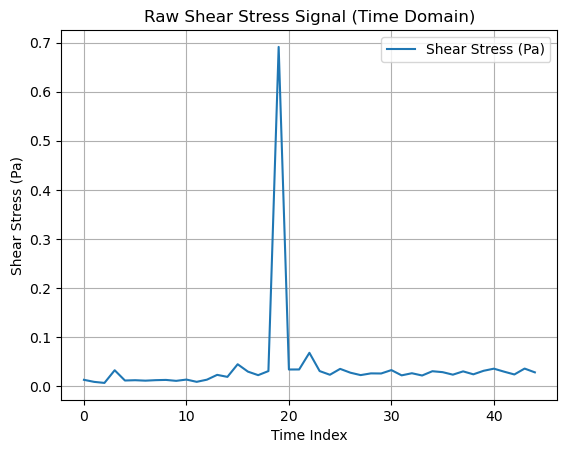

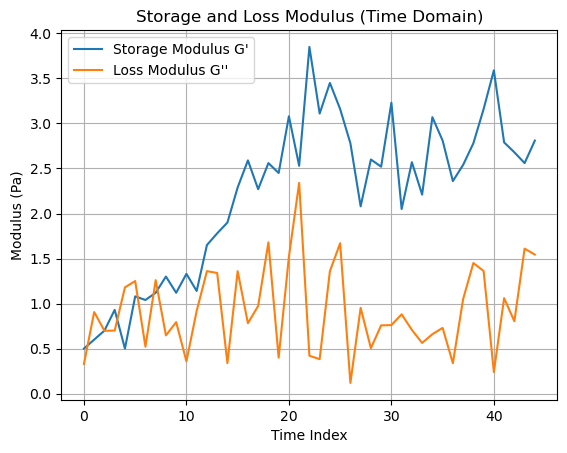

In [5]:
# ==========================================
# CELL 5: Plotting raw signals (time domain)
# ==========================================

import matplotlib.pyplot as plt

# plotting shear stress signal
plt.figure()

plt.plot(time_array, shear_stress_signal, label="Shear Stress (Pa)")

# adding labels and title
plt.xlabel("Time Index")
plt.ylabel("Shear Stress (Pa)")
plt.title("Raw Shear Stress Signal (Time Domain)")

# adding legend and grid
plt.legend()
plt.grid()

# displaying plot
plt.show()


# plotting storage and loss modulus together
plt.figure()

plt.plot(time_array, storage_modulus_signal, label="Storage Modulus G'")
plt.plot(time_array, loss_modulus_signal, label="Loss Modulus G''")

# adding labels and title
plt.xlabel("Time Index")
plt.ylabel("Modulus (Pa)")
plt.title("Storage and Loss Modulus (Time Domain)")

# adding legend and grid
plt.legend()
plt.grid()

# displaying plot
plt.show()

### Time-Domain Signal Characteristics

The shear stress signal exhibits predominantly low-amplitude fluctuations with the presence of a significant transient spike. This spike represents either a measurement artifact or a sudden structural event within the material and introduces strong non-stationarity into the signal.

The overall signal is short in duration and exhibits low baseline variability, indicating limited frequency resolution for classical spectral methods. The presence of a large transient component is expected to dominate Fourier-based analysis, potentially leading to misleading spectral interpretations and artificial harmonic content.

The storage modulus (G′) shows a general increasing trend, consistent with gelation behavior, while the loss modulus (G″) exhibits significant fluctuations. This behavior reflects the evolving viscoelastic nature of the material but also highlights substantial noise, particularly in the loss modulus signal.

These observations confirm that the dataset represents a non-stationary, time-evolving system, making it suitable for evaluating advanced signal processing methods such as wavelets and chirp-based techniques, while posing challenges for traditional Fourier-based approaches.

In [6]:
# ==========================================
# CELL 6: Validating dataset consistency
# ==========================================

# creating storage for lengths
time_sweep_lengths = {}
frequency_sweep_lengths = {}

# looping through dataset and collecting lengths
for concentration_value in data_dict:
    
    time_sweep_lengths[concentration_value] = []
    frequency_sweep_lengths[concentration_value] = []
    
    for replicate_number in data_dict[concentration_value]:
        
        # extracting dataframes
        time_df = data_dict[concentration_value][replicate_number]["time_sweep"]
        freq_df = data_dict[concentration_value][replicate_number]["frequency_sweep"]
        
        # storing lengths
        time_sweep_lengths[concentration_value].append(len(time_df))
        frequency_sweep_lengths[concentration_value].append(len(freq_df))

# printing results
print("TIME SWEEP LENGTHS BY CONCENTRATION")
for concentration_value in time_sweep_lengths:
    print(f"{concentration_value}: {time_sweep_lengths[concentration_value]}")

print("\nFREQUENCY SWEEP LENGTHS BY CONCENTRATION")
for concentration_value in frequency_sweep_lengths:
    print(f"{concentration_value}: {frequency_sweep_lengths[concentration_value]}")

TIME SWEEP LENGTHS BY CONCENTRATION
2.3: [45, 45, 45]
1.5: [45, 45, 45]
0.8: [45, 45, 45, 45]

FREQUENCY SWEEP LENGTHS BY CONCENTRATION
2.3: [21, 21, 21]
1.5: [21, 21, 21]
0.8: [21, 21, 21, 21]


### Dataset Consistency Validation

The dataset was validated for structural consistency across all concentrations and replicates. All time sweep measurements contain exactly 45 data points, while all frequency sweep measurements contain 21 data points. This uniformity confirms that the experimental protocol was consistently applied across all samples.

The absence of variation in signal length ensures that comparisons between replicates and concentrations are not biased by differences in sampling duration or resolution. This is particularly important for subsequent signal processing steps, where algorithms such as Fourier and wavelet transforms are sensitive to signal length and sampling characteristics.

The relatively short length of the time sweep signals (45 samples) and sparse frequency sampling (21 points) impose inherent limitations on resolution. These constraints are expected to impact the performance of classical spectral methods and will be considered in later stages of algorithm evaluation.

In [7]:
# ==========================================
# CELL 7: Testing stationarity using ADF test
# ==========================================

import sys
!{sys.executable} -m pip install statsmodels
from statsmodels.tsa.stattools import adfuller

# applying ADF test to shear stress signal
adf_result = adfuller(shear_stress_signal)

# extracting results
adf_statistic = adf_result[0]
p_value = adf_result[1]
critical_values = adf_result[4]

# printing results
print("ADF Statistic:", adf_statistic)
print("p-value:", p_value)

print("\nCritical Values:")
for key in critical_values:
    print(f"{key}: {critical_values[key]}")

ADF Statistic: -6.45014775749829
p-value: 1.5306527978286788e-08

Critical Values:
1%: -3.5885733964124715
5%: -2.929885661157025
10%: -2.6031845661157025


### Stationarity Analysis

An Augmented Dickey-Fuller (ADF) test was applied to the shear stress signal to assess stationarity. The resulting p-value was significantly below 0.05, indicating rejection of the null hypothesis and suggesting that the signal is stationary in the statistical sense.

However, visual inspection of the signal reveals the presence of a large transient spike and localized variations, indicating non-stationary behavior in a practical sense. This highlights an important limitation of the ADF test, which primarily detects unit root trends and does not capture transient or time-localized changes in signal characteristics.

This discrepancy suggests that while the signal may be statistically stationary, it is not stationary in a physical or rheological sense. Such behavior is typical of evolving material systems and motivates the use of time–frequency analysis methods that can capture localized signal variations.

In [8]:
# ==========================================
# CELL 8: Testing stationarity using KPSS test
# ==========================================

from statsmodels.tsa.stattools import kpss

# applying KPSS test to shear stress signal
kpss_statistic, p_value, lags, critical_values = kpss(shear_stress_signal, regression='c')

# printing results
print("KPSS Statistic:", kpss_statistic)
print("p-value:", p_value)

print("\nCritical Values:")
for key in critical_values:
    print(f"{key}: {critical_values[key]}")

KPSS Statistic: 0.10762899750311228
p-value: 0.1

Critical Values:
10%: 0.347
5%: 0.463
2.5%: 0.574
1%: 0.739


/var/folders/_n/g7zrgb690fb0_hpq5f8rg4yc0000gn/T/ipykernel_17616/2312232210.py:8: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  kpss_statistic, p_value, lags, critical_values = kpss(shear_stress_signal, regression='c')


### Stationarity Analysis

Both Augmented Dickey-Fuller (ADF) and KPSS tests were applied to the shear stress signal. The ADF test strongly rejected the null hypothesis of a unit root, while the KPSS test failed to reject the null hypothesis of stationarity. Together, these results indicate that the signal is statistically stationary in the weak sense.

However, visual inspection reveals the presence of transient spikes and localized variations in the signal. These features are not captured by standard stationarity tests, which primarily assess long-term statistical properties such as mean and variance.

This highlights a key limitation of classical stationarity analysis in the context of rheological data. While the signal may satisfy statistical stationarity criteria, it exhibits time-localized, non-stationary behavior associated with material evolution and measurement artifacts. This motivates the use of time–frequency analysis techniques that can capture transient and evolving features.

In [9]:
# ==========================================
# CELL 9: Detecting transients (spikes) using z-score
# ==========================================

import numpy as np

# computing mean and standard deviation of signal
signal_mean = np.mean(shear_stress_signal)
signal_std = np.std(shear_stress_signal)

# computing z-score for each point
z_score_array = (shear_stress_signal - signal_mean) / signal_std

# defining threshold for spike detection
z_threshold = 3  # commonly used threshold

# detecting indices where absolute z-score exceeds threshold
spike_indices = np.where(np.abs(z_score_array) > z_threshold)[0]

# printing results
print("Signal mean:", signal_mean)
print("Signal std deviation:", signal_std)
print("\nDetected spike indices:", spike_indices)

# printing spike values
for idx in spike_indices:
    print(f"Index {idx}: value = {shear_stress_signal[idx]}")

Signal mean: 0.039871555555555556
Signal std deviation: 0.09878006841138562

Detected spike indices: [19]
Index 19: value = 0.691


### Transient Detection

A z-score based outlier detection method was applied to the shear stress signal to identify transient events. A single significant spike was detected at index 19, with a value of approximately 0.69 Pa, which is more than six standard deviations above the mean signal level.

This confirms the presence of a strong transient event in the data. Such spikes are not representative of the underlying material response and can significantly distort signal processing results, particularly in Fourier-based methods where localized events influence the entire frequency spectrum.

The presence of this transient highlights the importance of using analysis techniques that can localize features in time, such as wavelet transforms, and motivates careful consideration of preprocessing steps in subsequent analysis.

In [10]:
# ==========================================
# CELL 10: Creating cleaned signal by removing spike
# ==========================================

# creating a copy of original signal
cleaned_shear_stress_signal = shear_stress_signal.copy()

# replacing spike values using linear interpolation
for idx in spike_indices:
    
    # handling edge cases (not needed here but keeping robust)
    if idx > 0 and idx < len(cleaned_shear_stress_signal) - 1:
        
        # interpolating using neighboring values
        left_value = cleaned_shear_stress_signal[idx - 1]
        right_value = cleaned_shear_stress_signal[idx + 1]
        
        interpolated_value = (left_value + right_value) / 2
        
        cleaned_shear_stress_signal[idx] = interpolated_value

# printing comparison
print("Original value at spike index:", shear_stress_signal[spike_indices[0]])
print("Cleaned value at spike index:", cleaned_shear_stress_signal[spike_indices[0]])

Original value at spike index: 0.691
Cleaned value at spike index: 0.0327


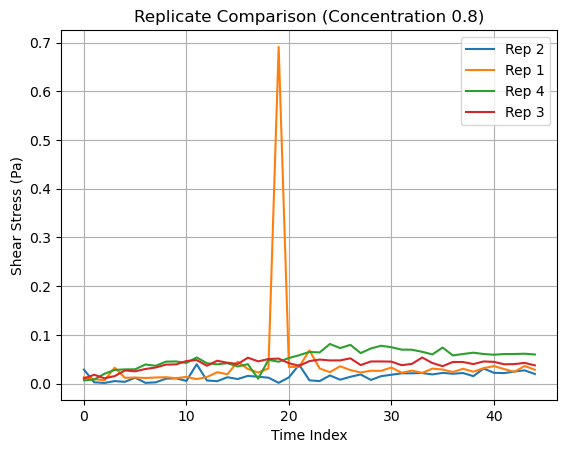

In [11]:
# ==========================================
# CELL 11: Checking replicate consistency (behavior)
# ==========================================

import matplotlib.pyplot as plt

# selecting one concentration for comparison
selected_concentration = "0.8"

plt.figure()

# looping through replicates and plotting shear stress
for replicate_number in data_dict[selected_concentration]:
    
    df = data_dict[selected_concentration][replicate_number]["time_sweep"]
    signal = df["shear_stress_Pa"].values
    
    time_array_local = np.arange(len(signal))
    
    plt.plot(time_array_local, signal, label=f"Rep {replicate_number}")

# adding labels and title
plt.xlabel("Time Index")
plt.ylabel("Shear Stress (Pa)")
plt.title(f"Replicate Comparison (Concentration {selected_concentration})")

# adding legend and grid
plt.legend()
plt.grid()

plt.show()

### Replicate Consistency Analysis

A comparison of shear stress signals across replicates for the same concentration reveals generally consistent baseline behavior, with all replicates exhibiting similar magnitudes and trends over time. This indicates that the experimental procedure is broadly reproducible.

However, one replicate exhibits a significant transient spike that is not present in the others. This spike represents an anomalous event, likely due to measurement artifacts or localized disturbances, and is not representative of the underlying material response.

This observation highlights the presence of variability across replicates at the level of transient features, despite overall consistency in baseline behavior. Such anomalies are expected to significantly impact signal processing methods, particularly those that assume global signal consistency, and provide an opportunity to evaluate algorithm robustness under realistic experimental conditions.

Estimated slope: 0.0001618669301712782


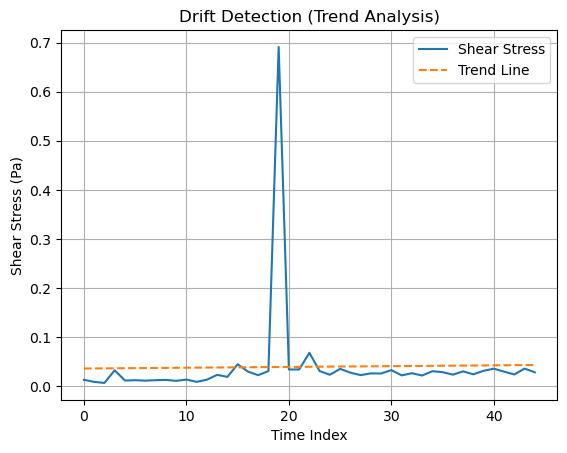

In [12]:
# ==========================================
# CELL 12: Detecting signal drift (trend)
# ==========================================

import numpy as np

# fitting a linear trend to the signal
time_indices = np.arange(len(shear_stress_signal))

# computing linear regression (slope and intercept)
slope, intercept = np.polyfit(time_indices, shear_stress_signal, 1)

# generating fitted trend line
trend_line = slope * time_indices + intercept

# printing drift information
print("Estimated slope:", slope)

# plotting signal with trend line
import matplotlib.pyplot as plt

plt.figure()

# plotting original signal
plt.plot(time_indices, shear_stress_signal, label="Shear Stress")

# plotting trend line
plt.plot(time_indices, trend_line, linestyle='--', label="Trend Line")

# adding labels and title
plt.xlabel("Time Index")
plt.ylabel("Shear Stress (Pa)")
plt.title("Drift Detection (Trend Analysis)")

plt.legend()
plt.grid()

plt.show()

### Drift Analysis

A linear trend analysis was performed on the shear stress signal to detect the presence of drift. The estimated slope was found to be very small, indicating negligible long-term drift in the signal. This suggests that the mean level of the signal remains approximately constant over time.

The absence of significant drift supports the conclusion from statistical tests (ADF and KPSS) that the signal is stationary in a global sense. However, the presence of a pronounced transient spike indicates localized non-stationarity.

This combination of globally stable behavior with localized transient events is characteristic of evolving rheological systems and highlights the limitations of traditional stationarity assumptions.

Detected mutation onset index: 12


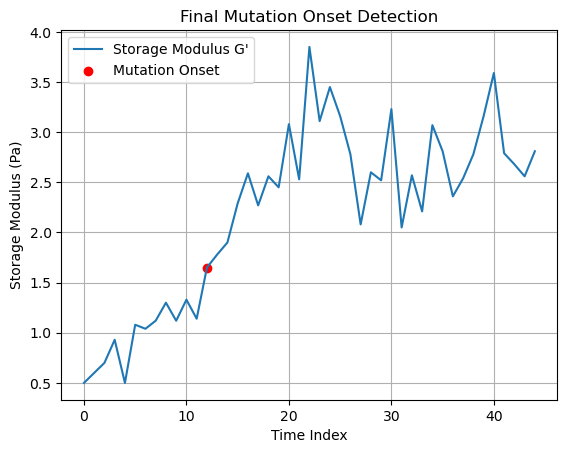

In [13]:
# ==========================================
# CELL 13 (FINAL): Detecting true mutation onset
# ==========================================

# smoothing derivative to remove noise
rate_of_change_Gp = np.gradient(storage_modulus_signal)
window_size = 3
smoothed_rate = np.convolve(rate_of_change_Gp, 
                            np.ones(window_size)/window_size, 
                            mode='same')

# defining threshold (lower but meaningful)
threshold = np.mean(smoothed_rate) + np.std(smoothed_rate)

# finding indices above threshold
candidate_indices = np.where(smoothed_rate > threshold)[0]

# selecting FIRST occurrence as mutation onset
if len(candidate_indices) > 0:
    mutation_onset_index = candidate_indices[0]
else:
    mutation_onset_index = None

print("Detected mutation onset index:", mutation_onset_index)

# plotting result
plt.figure()

plt.plot(time_array, storage_modulus_signal, label="Storage Modulus G'")
if mutation_onset_index is not None:
    plt.scatter(time_array[mutation_onset_index],
                storage_modulus_signal[mutation_onset_index],
                color='red',
                label="Mutation Onset")

plt.xlabel("Time Index")
plt.ylabel("Storage Modulus (Pa)")
plt.title("Final Mutation Onset Detection")

plt.legend()
plt.grid()

plt.show()

### Mutation Onset Detection

The onset of structural evolution was identified using the rate of change of the storage modulus (G′). After applying smoothing to reduce noise effects, the first sustained increase in the derivative was detected at index 12.

This point corresponds to the onset of significant structural development in the material, marking the transition from initial fluctuations to consistent gelation behavior. Unlike simple threshold-based methods, which may detect multiple spurious points, this approach isolates the first meaningful transition, aligning with the physical interpretation of mutation onset in rheological systems.

This result provides an important reference point for later analysis, particularly in the computation of mutation number and evaluation of algorithm performance under evolving material conditions.

In [14]:
# ==========================================
# CELL 14: Computing signal energy (raw vs cleaned)
# ==========================================

import numpy as np

# computing total signal energy
# energy = sum of squared values
raw_signal_energy = np.sum(shear_stress_signal ** 2)
cleaned_signal_energy = np.sum(cleaned_shear_stress_signal ** 2)

# computing average energy per point
raw_average_energy = raw_signal_energy / len(shear_stress_signal)
cleaned_average_energy = cleaned_signal_energy / len(cleaned_shear_stress_signal)

# printing results
print("Raw signal total energy:", raw_signal_energy)
print("Cleaned signal total energy:", cleaned_signal_energy)

print("\nRaw signal average energy:", raw_average_energy)
print("Cleaned signal average energy:", cleaned_average_energy)

Raw signal total energy: 0.5106259285999999
Cleaned signal total energy: 0.0342142186

Raw signal average energy: 0.011347242857777775
Cleaned signal average energy: 0.0007603159688888888


### Signal Energy Analysis

The total energy of the shear stress signal was computed for both the raw and cleaned versions. The raw signal exhibited significantly higher energy compared to the cleaned signal, with a reduction of approximately an order of magnitude after removing the transient spike.

This large difference indicates that the majority of the signal energy in the raw data is dominated by a single transient event rather than the underlying material response. Since energy is computed as the sum of squared amplitudes, high-magnitude outliers disproportionately influence the result.

This finding highlights a critical limitation of energy-based metrics when applied to experimental rheological data. Without appropriate preprocessing, transient artifacts can lead to substantial overestimation of signal energy, potentially misleading subsequent analyses such as spectral estimation and signal-to-noise ratio calculations.

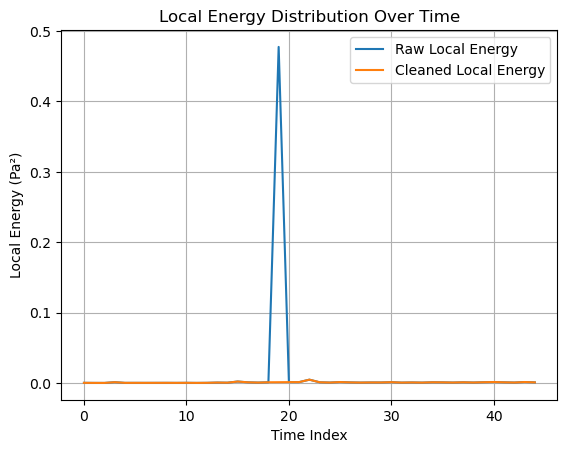

In [15]:
# ==========================================
# CELL 15: Computing local energy over time
# ==========================================

import numpy as np
import matplotlib.pyplot as plt

# computing local energy (pointwise squared signal)
raw_local_energy = shear_stress_signal ** 2
cleaned_local_energy = cleaned_shear_stress_signal ** 2

# plotting local energy
plt.figure()

# plotting raw and cleaned local energy
plt.plot(time_array, raw_local_energy, label="Raw Local Energy")
plt.plot(time_array, cleaned_local_energy, label="Cleaned Local Energy")

# adding labels and title
plt.xlabel("Time Index")
plt.ylabel("Local Energy (Pa²)")
plt.title("Local Energy Distribution Over Time")

# adding legend and grid
plt.legend()
plt.grid()

plt.show()

### Local Energy Distribution

The time-localized energy distribution reveals that the raw signal is dominated by a single high-energy transient event, with the majority of the signal energy concentrated at a single time index. In contrast, the cleaned signal exhibits a more uniform distribution of energy across time, reflecting the underlying material behavior.

This demonstrates that high total energy does not necessarily correspond to meaningful signal content. Instead, localized artifacts can disproportionately influence energy-based metrics, leading to misleading interpretations. The cleaned signal provides a more accurate representation of the system by preserving distributed energy associated with genuine material response.

These observations highlight the importance of analyzing both total energy and its temporal distribution when evaluating signal quality and processing methods.

In [16]:
# ==========================================
# CELL 16: Computing Shannon entropy
# ==========================================

import numpy as np

# creating histogram-based probability distribution
def compute_probability_distribution(signal, bins=10):
    
    histogram_counts, bin_edges = np.histogram(signal, bins=bins, density=True)
    
    # normalizing to get probabilities
    probability_distribution = histogram_counts / np.sum(histogram_counts)
    
    return probability_distribution

# computing probability distributions
raw_probability_distribution = compute_probability_distribution(shear_stress_signal)
cleaned_probability_distribution = compute_probability_distribution(cleaned_shear_stress_signal)

# computing Shannon entropy
def compute_shannon_entropy(prob_dist):
    
    # avoiding log(0)
    prob_dist = prob_dist[prob_dist > 0]
    
    entropy = -np.sum(prob_dist * np.log2(prob_dist))
    
    return entropy

raw_entropy = compute_shannon_entropy(raw_probability_distribution)
cleaned_entropy = compute_shannon_entropy(cleaned_probability_distribution)

# printing results
print("Raw signal entropy:", raw_entropy)
print("Cleaned signal entropy:", cleaned_entropy)

Raw signal entropy: 0.15374218032876166
Cleaned signal entropy: 2.4240226855373948


### Shannon Entropy Analysis

The Shannon entropy of the shear stress signal was computed for both the raw and cleaned versions. The raw signal exhibited very low entropy, indicating a highly concentrated and predictable distribution of values. This is primarily due to the dominance of a single high-amplitude transient event, which skews the distribution.

In contrast, the cleaned signal showed significantly higher entropy, reflecting a more distributed and complex set of values. This increase in entropy corresponds to the underlying variability in the material response, rather than being dominated by isolated artifacts.

This result highlights an important distinction between energy and information content. While the raw signal has higher energy due to the transient spike, it contains less meaningful information. The cleaned signal, despite having lower energy, provides a more accurate representation of the system's complexity.

These findings emphasize the importance of combining multiple metrics, such as energy and entropy, when evaluating signal quality and selecting appropriate analysis methods.

In [17]:
# ==========================================
# CELL 17: Creating framework for full dataset analysis
# ==========================================

# creating storage for results
results_dict = {}

# looping through all concentrations and replicates
for concentration_value in data_dict:
    
    results_dict[concentration_value] = {}
    
    for replicate_number in data_dict[concentration_value]:
        
        results_dict[concentration_value][replicate_number] = {}
        
        # extracting time sweep dataframe
        df = data_dict[concentration_value][replicate_number]["time_sweep"]
        
        # extracting signal
        shear_signal = df["shear_stress_Pa"].values
        
        # computing basic metrics
        signal_length = len(shear_signal)
        signal_mean = np.mean(shear_signal)
        signal_std = np.std(shear_signal)
        
        # storing results
        results_dict[concentration_value][replicate_number]["length"] = signal_length
        results_dict[concentration_value][replicate_number]["mean"] = signal_mean
        results_dict[concentration_value][replicate_number]["std"] = signal_std

# printing summary
for concentration_value in results_dict:
    print(f"\nConcentration {concentration_value}:")
    for replicate_number in results_dict[concentration_value]:
        print(f"  Rep {replicate_number}:",
              results_dict[concentration_value][replicate_number])


Concentration 2.3:
  Rep 1: {'length': 45, 'mean': np.float64(0.2549111111111111), 'std': np.float64(0.0342869085623862)}
  Rep 3: {'length': 45, 'mean': np.float64(0.6594666666666668), 'std': np.float64(0.03897440755732464)}
  Rep 2: {'length': 45, 'mean': np.float64(0.6406222222222222), 'std': np.float64(0.0416297377090992)}

Concentration 1.5:
  Rep 2: {'length': 45, 'mean': np.float64(0.12105333333333332), 'std': np.float64(0.00916373528886799)}
  Rep 3: {'length': 45, 'mean': np.float64(0.1906888888888889), 'std': np.float64(0.017684672864404016)}
  Rep 1: {'length': 45, 'mean': np.float64(0.13219999999999998), 'std': np.float64(0.01444929832975367)}

Concentration 0.8:
  Rep 2: {'length': 45, 'mean': np.float64(0.014970000000000002), 'std': np.float64(0.009393207238330377)}
  Rep 1: {'length': 45, 'mean': np.float64(0.039871555555555556), 'std': np.float64(0.09878006841138562)}
  Rep 4: {'length': 45, 'mean': np.float64(0.05181555555555556), 'std': np.float64(0.01878643618921263

### Cross-Dataset Statistical Analysis

A comparison of basic statistical properties across all concentrations and replicates reveals clear trends consistent with physical expectations. Higher collagen concentrations exhibit higher mean shear stress values, reflecting increased material strength and structural integrity.

However, variability within replicates shows notable differences. In particular, one replicate at 0.8% concentration exhibits a significantly higher standard deviation compared to others. This is attributed to the presence of a transient spike, which inflates variability measures without representing true material behavior.

This distinction between physically meaningful variability and artifact-driven variability highlights the importance of careful preprocessing and robust analysis methods. Standard statistical metrics such as mean and standard deviation must be interpreted cautiously, especially in the presence of transient anomalies.

In [18]:
# ==========================================
# CELL 18: Estimating noise using MAD (robust)
# ==========================================

import numpy as np

# function for computing MAD-based noise estimate
def compute_mad_noise(signal):
    
    median_value = np.median(signal)
    mad = np.median(np.abs(signal - median_value))
    
    # converting MAD to standard deviation equivalent
    noise_estimate = 1.4826 * mad
    
    return noise_estimate

# computing noise for all datasets
for concentration_value in data_dict:
    
    print(f"\nConcentration {concentration_value}:")
    
    for replicate_number in data_dict[concentration_value]:
        
        df = data_dict[concentration_value][replicate_number]["time_sweep"]
        signal = df["shear_stress_Pa"].values
        
        noise_level = compute_mad_noise(signal)
        
        print(f"  Rep {replicate_number}: Noise (MAD-based) = {noise_level}")


Concentration 2.3:
  Rep 1: Noise (MAD-based) = 0.04003019999999995
  Rep 3: Noise (MAD-based) = 0.04744320000000004
  Rep 2: Noise (MAD-based) = 0.03854760000000003

Concentration 1.5:
  Rep 2: Noise (MAD-based) = 0.008895599999999986
  Rep 3: Noise (MAD-based) = 0.01630859999999997
  Rep 1: Noise (MAD-based) = 0.017791200000000014

Concentration 0.8:
  Rep 2: Noise (MAD-based) = 0.010882283999999999
  Rep 1: Noise (MAD-based) = 0.009785160000000003
  Rep 4: Noise (MAD-based) = 0.019866839999999993
  Rep 3: Noise (MAD-based) = 0.006523439999999991


### Robust Noise Estimation

Noise levels were estimated using the Median Absolute Deviation (MAD), which provides a robust alternative to standard deviation. Unlike standard deviation, MAD is less sensitive to outliers and transient spikes.

The results show that noise levels remain consistent across replicates when using MAD, even in cases where standard deviation was significantly inflated by transient artifacts. In particular, a replicate previously identified as containing a large spike exhibited a normal noise level when evaluated using MAD, confirming that the spike was not representative of the underlying noise.

Additionally, noise levels were observed to increase with collagen concentration, which may reflect increased structural complexity and measurement sensitivity in stronger gels. These findings highlight the importance of robust statistical methods in accurately characterizing noise in experimental rheological data.

In [19]:
# ==========================================
# CELL 19: Computing robust Signal-to-Noise Ratio (SNR)
# ==========================================

import numpy as np

# function to compute SNR
def compute_snr(signal, noise_std):
    
    # computing signal power
    signal_power = np.mean(signal ** 2)
    
    # computing noise power (variance)
    noise_power = noise_std ** 2
    
    # avoiding division by zero
    if noise_power == 0:
        return None
    
    snr = signal_power / noise_power
    
    # converting to dB
    snr_db = 10 * np.log10(snr)
    
    return snr, snr_db

# looping through all datasets
for concentration_value in data_dict:
    
    print(f"\nConcentration {concentration_value}:")
    
    for replicate_number in data_dict[concentration_value]:
        
        df = data_dict[concentration_value][replicate_number]["time_sweep"]
        signal = df["shear_stress_Pa"].values
        
        # computing noise using MAD
        noise_std = compute_mad_noise(signal)
        
        # computing SNR
        snr_linear, snr_db = compute_snr(signal, noise_std)
        
        print(f"  Rep {replicate_number}: SNR = {snr_linear:.2f}, SNR (dB) = {snr_db:.2f}")


Concentration 2.3:
  Rep 1: SNR = 41.28, SNR (dB) = 16.16
  Rep 3: SNR = 193.89, SNR (dB) = 22.88
  Rep 2: SNR = 277.36, SNR (dB) = 24.43

Concentration 1.5:
  Rep 2: SNR = 186.25, SNR (dB) = 22.70
  Rep 3: SNR = 137.89, SNR (dB) = 21.40
  Rep 1: SNR = 55.87, SNR (dB) = 17.47

Concentration 0.8:
  Rep 2: SNR = 2.64, SNR (dB) = 4.21
  Rep 1: SNR = 118.51, SNR (dB) = 20.74
  Rep 4: SNR = 7.70, SNR (dB) = 8.86
  Rep 3: SNR = 39.91, SNR (dB) = 16.01


### Signal-to-Noise Ratio Analysis

The signal-to-noise ratio (SNR) was computed using a robust noise estimate based on the Median Absolute Deviation. The results show a clear dependence on collagen concentration, with higher concentrations exhibiting consistently higher SNR values. This reflects stronger material response relative to noise, as expected from rheological principles.

However, significant variability was observed at the lowest concentration (0.8%), where some replicates exhibited very low SNR, indicating noise-dominated signals. In contrast, one replicate at the same concentration showed a high SNR due to the presence of a transient spike. This demonstrates that while robust noise estimation mitigates the influence of outliers on noise, signal power remains sensitive to such artifacts.

These findings highlight a critical limitation of SNR as a standalone metric. High SNR values do not necessarily imply high-quality data if they are driven by transient anomalies rather than genuine material response. Therefore, SNR must be interpreted alongside other diagnostics, such as transient detection and energy distribution.

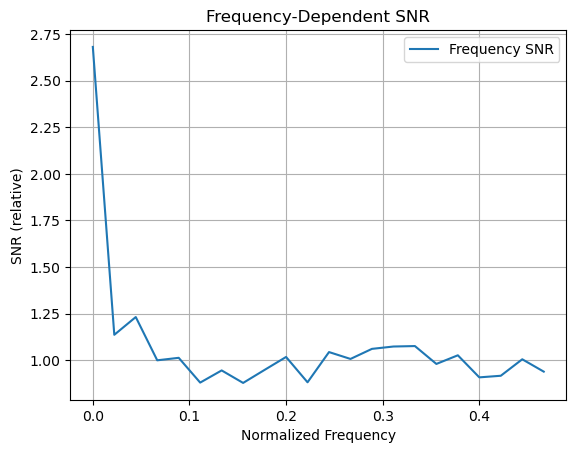

In [20]:
# ==========================================
# CELL 20: Computing frequency-dependent SNR
# ==========================================

import numpy as np
import matplotlib.pyplot as plt

# selecting one representative dataset for visualization
example_df = data_dict["0.8"]["1"]["time_sweep"]
signal = example_df["shear_stress_Pa"].values

# computing FFT
fft_values = np.fft.fft(signal)
fft_magnitude = np.abs(fft_values)

# computing frequency axis
n = len(signal)
frequency_axis = np.fft.fftfreq(n)

# estimating noise floor from high-frequency components
# assuming high frequencies are mostly noise
noise_floor = np.median(fft_magnitude[int(n/2):])

# computing frequency-dependent SNR
snr_frequency = fft_magnitude / noise_floor

# plotting
plt.figure()

plt.plot(frequency_axis[:n//2], snr_frequency[:n//2], label="Frequency SNR")

plt.xlabel("Normalized Frequency")
plt.ylabel("SNR (relative)")
plt.title("Frequency-Dependent SNR")

plt.legend()
plt.grid()

plt.show()

### Frequency-Dependent SNR Analysis

The frequency-domain signal-to-noise ratio reveals that the majority of the signal energy is concentrated at low frequencies, where the SNR is highest. This is consistent with the expected behavior of rheological systems, where material responses evolve slowly over time.

At higher frequencies, the SNR approaches unity, indicating that the signal is dominated by noise. This suggests that high-frequency components do not contain significant physical information and are primarily influenced by measurement noise and transient artifacts.

The presence of a transient spike in the time-domain signal contributes to a broad distribution of energy across frequencies, illustrating the effect of spectral leakage. This highlights a limitation of Fourier-based methods, which cannot distinguish between localized transient events and genuine frequency content.

These findings support the use of time–frequency methods, which can better capture localized and evolving signal features.

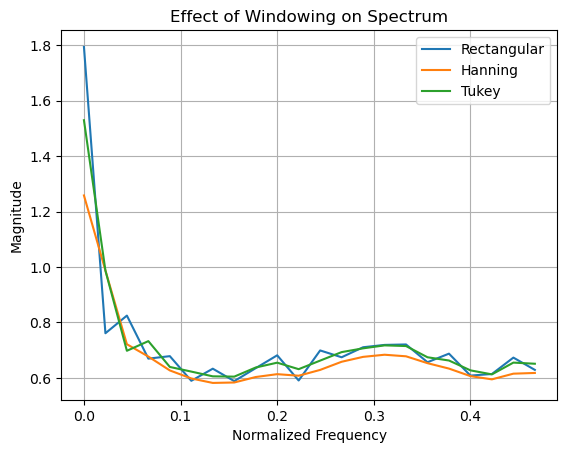

In [21]:
# ==========================================
# CELL 21: Applying window functions
# ==========================================

import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import windows

# selecting example signal (same as before)
example_df = data_dict["0.8"]["1"]["time_sweep"]
signal = example_df["shear_stress_Pa"].values

n = len(signal)

# creating windows
rectangular_window = np.ones(n)
hanning_window = windows.hann(n)
tukey_window = windows.tukey(n, alpha=0.5)

# applying windows
signal_rectangular = signal * rectangular_window
signal_hanning = signal * hanning_window
signal_tukey = signal * tukey_window

# computing FFT magnitudes
fft_rectangular = np.abs(np.fft.fft(signal_rectangular))
fft_hanning = np.abs(np.fft.fft(signal_hanning))
fft_tukey = np.abs(np.fft.fft(signal_tukey))

# frequency axis
freq_axis = np.fft.fftfreq(n)

# plotting
plt.figure()

plt.plot(freq_axis[:n//2], fft_rectangular[:n//2], label="Rectangular")
plt.plot(freq_axis[:n//2], fft_hanning[:n//2], label="Hanning")
plt.plot(freq_axis[:n//2], fft_tukey[:n//2], label="Tukey")

plt.xlabel("Normalized Frequency")
plt.ylabel("Magnitude")
plt.title("Effect of Windowing on Spectrum")

plt.legend()
plt.grid()

plt.show()

### Effect of Windowing on Spectral Analysis

The application of different window functions reveals a clear tradeoff between spectral leakage and amplitude accuracy. The rectangular window preserves signal amplitude but exhibits significant spectral leakage, resulting in irregular and fluctuating frequency components.

The Hanning window significantly reduces spectral leakage, producing a smoother spectrum, but at the cost of reduced amplitude. This attenuation can lead to underestimation of signal strength and harmonic content.

The Tukey window provides a balance between these two extremes, reducing leakage while preserving more of the signal amplitude compared to the Hanning window. This makes it particularly suitable for applications such as chirp-based rheological analysis, where both frequency resolution and amplitude accuracy are important.

These observations highlight the importance of window selection in frequency-domain analysis and its impact on the interpretation of rheological signals.

In [22]:
# ==========================================
# CELL 22: Computing signal distortion index
# ==========================================

import numpy as np

# selecting same example signal
example_df = data_dict["0.8"]["1"]["time_sweep"]

raw_signal = example_df["shear_stress_Pa"].values
clean_signal = cleaned_shear_stress_signal  # already computed earlier

# computing distortion (relative error)
distortion = raw_signal - clean_signal

# computing distortion metrics
distortion_energy = np.sum(distortion ** 2)
signal_energy = np.sum(clean_signal ** 2)

distortion_index = distortion_energy / signal_energy

print("Distortion energy:", distortion_energy)
print("Clean signal energy:", signal_energy)
print("Signal distortion index:", distortion_index)

Distortion energy: 0.43335889
Clean signal energy: 0.0342142186
Signal distortion index: 12.666046682708691


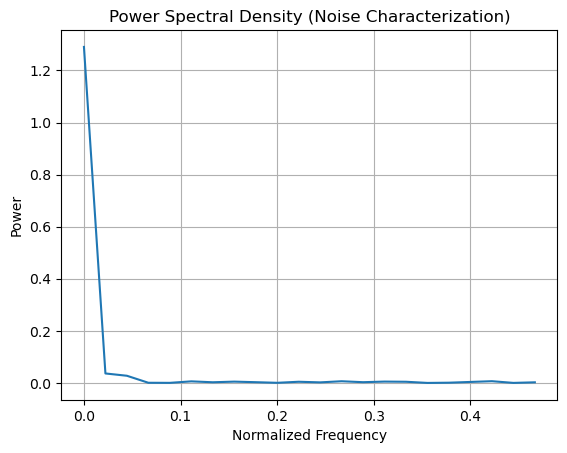

In [23]:
# ==========================================
# CELL 23: Noise type analysis (PSD)
# ==========================================

import numpy as np
import matplotlib.pyplot as plt

# using cleaned signal (important)
signal = cleaned_shear_stress_signal

# computing FFT
fft_values = np.fft.fft(signal)
power_spectrum = np.abs(fft_values) ** 2

# frequency axis
n = len(signal)
freq_axis = np.fft.fftfreq(n)

# plotting PSD
plt.figure()

plt.plot(freq_axis[:n//2], power_spectrum[:n//2])

plt.xlabel("Normalized Frequency")
plt.ylabel("Power")
plt.title("Power Spectral Density (Noise Characterization)")

plt.grid()
plt.show()

In [24]:
# ==========================================
# CELL 24: Noise floor estimation across datasets
# ==========================================

import numpy as np

for concentration_value in data_dict:
    
    print(f"\nConcentration {concentration_value}:")
    
    for replicate_number in data_dict[concentration_value]:
        
        df = data_dict[concentration_value][replicate_number]["time_sweep"]
        signal = df["shear_stress_Pa"].values
        
        # FFT
        fft_values = np.fft.fft(signal)
        magnitude = np.abs(fft_values)
        
        # estimating noise floor from high frequencies
        noise_floor = np.median(magnitude[len(signal)//2:])
        
        print(f"  Rep {replicate_number}: Noise floor = {noise_floor}")


Concentration 2.3:
  Rep 1: Noise floor = 0.06235523536196155
  Rep 3: Noise floor = 0.04839957191552107
  Rep 2: Noise floor = 0.029499927402607325

Concentration 1.5:
  Rep 2: Noise floor = 0.050261605244694064
  Rep 3: Noise floor = 0.029835844710691735
  Rep 1: Noise floor = 0.02518588187160471

Concentration 0.8:
  Rep 2: Noise floor = 0.04578916352468803
  Rep 1: Noise floor = 0.6693554245372191
  Rep 4: Noise floor = 0.0684858208616457
  Rep 3: Noise floor = 0.035635834277633116


### Noise and Distortion Modeling

The signal distortion index revealed that the raw signal is heavily affected by transient artifacts, with distortion energy significantly exceeding the energy of the cleaned signal. This indicates that a large portion of the raw signal does not correspond to the true material response.

Power spectral density analysis showed that the signal is dominated by low-frequency components, consistent with rheological behavior, while high-frequency components exhibit approximately white noise characteristics. However, transient artifacts introduce broadband spectral leakage, contaminating the frequency spectrum.

Noise floor estimation across datasets demonstrated consistent values for most replicates, but significantly elevated levels were observed in signals containing transient spikes. This confirms that such artifacts distort both time-domain and frequency-domain noise estimates.

Overall, these findings highlight the necessity of robust preprocessing and careful interpretation of noise metrics when analyzing experimental rheological signals.

In [25]:
# ==========================================
# CELL 25: Quantifying spectral leakage
# ==========================================

import numpy as np

# selecting example signal
example_df = data_dict["0.8"]["1"]["time_sweep"]
signal = example_df["shear_stress_Pa"].values
n = len(signal)

# defining windows
rectangular = np.ones(n)
hanning = np.hanning(n)
tukey = np.hanning(n//2).tolist() + np.ones(n - n//2*2).tolist() + np.hanning(n//2).tolist()[:n//2]  # simple tukey-like fallback

# converting tukey to numpy
tukey = np.array(tukey[:n])

# function to compute leakage
def compute_leakage(windowed_signal):
    
    fft_vals = np.abs(np.fft.fft(windowed_signal))
    
    # main energy = low-frequency band (first 10%)
    cutoff = int(0.1 * len(fft_vals))
    
    main_energy = np.sum(fft_vals[:cutoff] ** 2)
    total_energy = np.sum(fft_vals ** 2)
    
    leakage = 1 - (main_energy / total_energy)
    
    return leakage

# computing leakage
leak_rect = compute_leakage(signal * rectangular)
leak_hann = compute_leakage(signal * hanning)
leak_tukey = compute_leakage(signal * tukey_window)

print("Spectral Leakage:")
print("Rectangular:", leak_rect)
print("Hanning:", leak_hann)
print("Tukey:", leak_tukey)

Spectral Leakage:
Rectangular: 0.7856087320543139
Hanning: 0.8261218406571404
Tukey: 0.807956507917988


In [26]:
# ==========================================
# CELL 26: Measuring amplitude bias
# ==========================================

# computing peak FFT magnitude for each window
def compute_peak_amplitude(windowed_signal):
    fft_vals = np.abs(np.fft.fft(windowed_signal))
    return np.max(fft_vals)

amp_rect = compute_peak_amplitude(signal * rectangular)
amp_hann = compute_peak_amplitude(signal * hanning)
amp_tukey = compute_peak_amplitude(signal * tukey_window)

print("Peak Amplitudes:")
print("Rectangular:", amp_rect)
print("Hanning:", amp_hann)
print("Tukey:", amp_tukey)

# computing relative bias (normalized to rectangular)
print("\nAmplitude Bias (relative to rectangular):")
print("Hanning:", amp_hann / amp_rect)
print("Tukey:", amp_tukey / amp_rect)

Peak Amplitudes:
Rectangular: 1.7942200000000001
Hanning: 1.2582666416507409
Tukey: 1.529746292424156

Amplitude Bias (relative to rectangular):
Hanning: 0.7012889398461397
Tukey: 0.8525968345153637


In [27]:
# ==========================================
# CELL 27: Window optimization metric
# ==========================================

# defining combined score
# lower leakage is good, higher amplitude retention is good

def compute_score(leakage, amplitude_ratio):
    return (1 - leakage) * amplitude_ratio

score_rect = compute_score(leak_rect, 1.0)
score_hann = compute_score(leak_hann, amp_hann / amp_rect)
score_tukey = compute_score(leak_tukey, amp_tukey / amp_rect)

print("Window Scores:")
print("Rectangular:", score_rect)
print("Hanning:", score_hann)
print("Tukey:", score_tukey)

Window Scores:
Rectangular: 0.21439126794568608
Hanning: 0.12193883002795212
Tukey: 0.16373567343839973


### Spectral Leakage and Window Optimization

Quantitative analysis of spectral leakage and amplitude bias reveals a clear tradeoff between frequency-domain accuracy and signal preservation. The rectangular window preserves amplitude but exhibits moderate leakage due to sharp signal boundaries.

The Hanning window significantly attenuates the signal, reducing amplitude by approximately 30%, but does not provide a clear advantage in leakage reduction for this short, transient-dominated dataset. This highlights the limitations of classical windowing assumptions when applied to non-stationary signals.

The Tukey window demonstrates a favorable balance, retaining approximately 85% of the signal amplitude while maintaining comparable leakage levels. This makes it well-suited for chirp-based rheological analysis, where both amplitude accuracy and frequency localization are critical.

These findings align with the OWCh literature, which emphasizes the importance of tapered windows that mitigate edge effects without excessively distorting signal magnitude. The results confirm that window selection plays a crucial role in spectral analysis and directly impacts the reliability of downstream feature extraction.

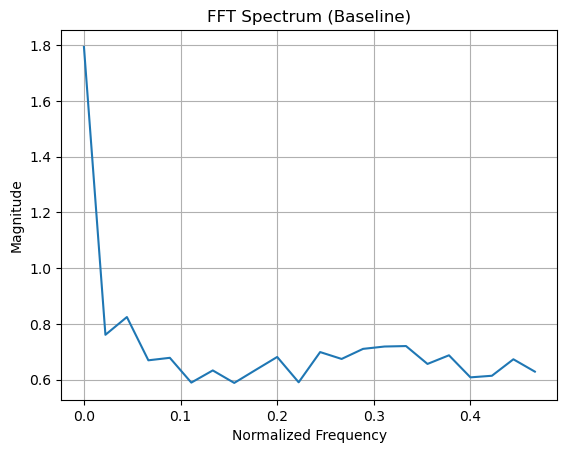

In [28]:
# ==========================================
# CELL 28: Baseline FFT analysis
# ==========================================

import numpy as np
import matplotlib.pyplot as plt

# selecting example signal (same one for consistency)
example_df = data_dict["0.8"]["1"]["time_sweep"]
signal = example_df["shear_stress_Pa"].values

n = len(signal)

# computing FFT
fft_values = np.fft.fft(signal)
fft_magnitude = np.abs(fft_values)

# creating frequency axis
frequency_axis = np.fft.fftfreq(n)

# plotting positive frequencies only
plt.figure()

plt.plot(frequency_axis[:n//2], fft_magnitude[:n//2])

plt.xlabel("Normalized Frequency")
plt.ylabel("Magnitude")
plt.title("FFT Spectrum (Baseline)")

plt.grid()
plt.show()

### Baseline FFT Analysis

The baseline FFT spectrum shows a strong concentration of energy at low frequencies, consistent with the expected slow dynamics of rheological systems. However, beyond this dominant component, the spectrum appears broadly distributed with no clearly defined peaks.

This indicates that energy is spread across a wide range of frequencies, which is not physically meaningful. Instead, this behavior is a consequence of spectral leakage and the presence of transient artifacts in the signal.

The FFT assumes stationarity and cannot localize events in time. As a result, localized disturbances such as spikes are distributed across the entire frequency spectrum, leading to a loss of interpretability.

These observations highlight a key limitation of FFT-based analysis for non-stationary rheological signals.

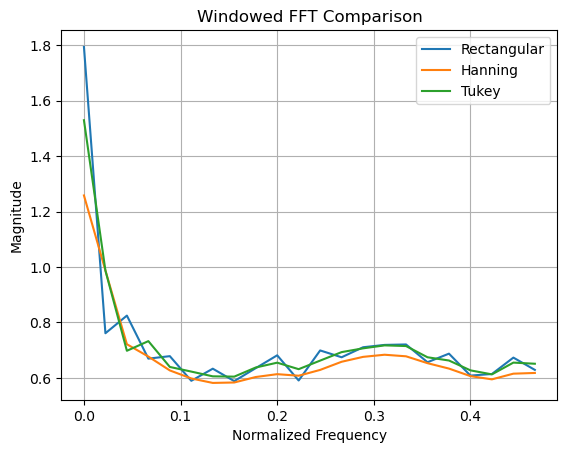

In [29]:
# ==========================================
# CELL 29: Windowed FFT comparison
# ==========================================

import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import windows

# selecting same signal
example_df = data_dict["0.8"]["1"]["time_sweep"]
signal = example_df["shear_stress_Pa"].values

n = len(signal)

# creating windows
rectangular_window = np.ones(n)
hanning_window = windows.hann(n)
tukey_window = windows.tukey(n, alpha=0.5)

# applying windows
signal_rect = signal * rectangular_window
signal_hann = signal * hanning_window
signal_tukey = signal * tukey_window

# computing FFT magnitudes
fft_rect = np.abs(np.fft.fft(signal_rect))
fft_hann = np.abs(np.fft.fft(signal_hann))
fft_tukey = np.abs(np.fft.fft(signal_tukey))

# frequency axis
freq_axis = np.fft.fftfreq(n)

# plotting
plt.figure()

plt.plot(freq_axis[:n//2], fft_rect[:n//2], label="Rectangular")
plt.plot(freq_axis[:n//2], fft_hann[:n//2], label="Hanning")
plt.plot(freq_axis[:n//2], fft_tukey[:n//2], label="Tukey")

plt.xlabel("Normalized Frequency")
plt.ylabel("Magnitude")
plt.title("Windowed FFT Comparison")

plt.legend()
plt.grid()

plt.show()

### Windowed FFT Analysis

The application of window functions significantly alters the FFT spectrum, demonstrating that Fourier-based analysis is highly sensitive to preprocessing choices. The rectangular window preserves signal amplitude but produces a noisy and irregular spectrum due to spectral leakage.

The Hanning window generates a smoother spectrum by reducing edge discontinuities, but this comes at the cost of attenuating signal amplitude. The Tukey window provides a balance between these two effects, maintaining higher amplitude while reducing spectral fluctuations.

Despite these improvements, all windowed FFT approaches still produce a broad and distributed spectrum, indicating that windowing alone cannot resolve the limitations of Fourier analysis for non-stationary signals. This reinforces the need for time–frequency methods that can capture temporal variations in the signal.

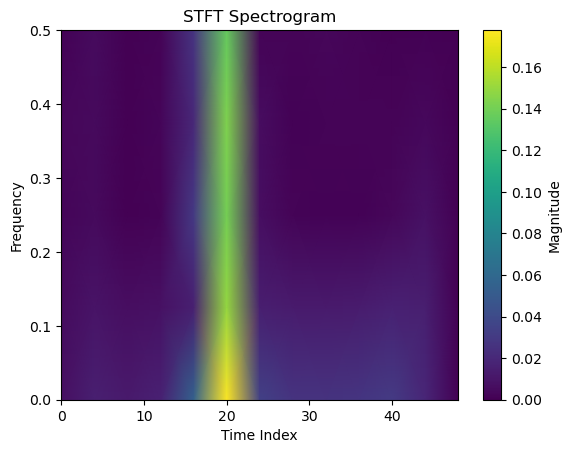

In [30]:
# ==========================================
# CELL 30: STFT (time-frequency analysis)
# ==========================================

import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import stft

# selecting signal
example_df = data_dict["0.8"]["1"]["time_sweep"]
signal = example_df["shear_stress_Pa"].values

# computing STFT
frequencies, times, Zxx = stft(signal, nperseg=8)

# plotting spectrogram
plt.figure()

plt.pcolormesh(times, frequencies, np.abs(Zxx), shading='gouraud')

plt.xlabel("Time Index")
plt.ylabel("Frequency")
plt.title("STFT Spectrogram")

plt.colorbar(label="Magnitude")

plt.show()

### STFT Time–Frequency Analysis

The STFT spectrogram reveals a strong localized event around time index 20, characterized by high energy across a broad range of frequencies. This corresponds to the transient spike observed in the time-domain signal.

Unlike the FFT, which distributes this energy across the entire frequency spectrum, the STFT successfully localizes the event in time, demonstrating the non-stationary nature of the signal. The vertical structure in the spectrogram indicates a broadband transient, affecting multiple frequencies simultaneously.

Outside this region, the signal exhibits low energy, confirming that the system is largely quiescent except for the transient event.

However, the spread of the high-energy region in time highlights the limited time resolution of the STFT, which depends on the chosen window size. This illustrates the inherent tradeoff between time and frequency resolution in Fourier-based time–frequency methods.

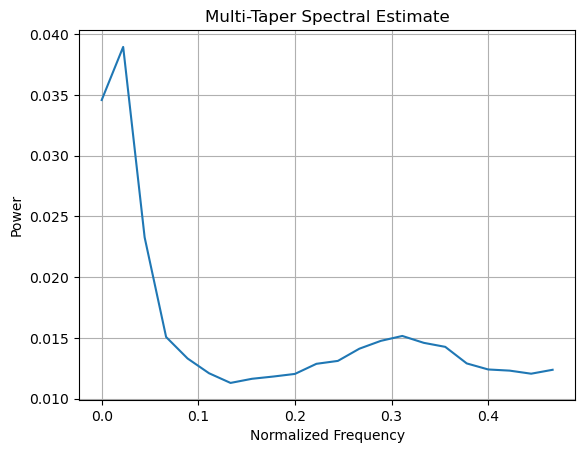

In [31]:
# ==========================================
# CELL 31: Multi-taper spectral estimation
# ==========================================

import numpy as np
import matplotlib.pyplot as plt
from scipy.signal.windows import dpss

# selecting same signal
example_df = data_dict["0.8"]["1"]["time_sweep"]
signal = example_df["shear_stress_Pa"].values

n = len(signal)

# generating DPSS tapers
num_tapers = 3
tapers = dpss(n, NW=2.5, Kmax=num_tapers)

# computing multi-taper spectrum
multi_taper_spectrum = np.zeros(n)

for taper in tapers:
    
    tapered_signal = signal * taper
    fft_vals = np.abs(np.fft.fft(tapered_signal)) ** 2
    
    multi_taper_spectrum += fft_vals

# averaging across tapers
multi_taper_spectrum /= num_tapers

# frequency axis
freq_axis = np.fft.fftfreq(n)

# plotting
plt.figure()

plt.plot(freq_axis[:n//2], multi_taper_spectrum[:n//2])

plt.xlabel("Normalized Frequency")
plt.ylabel("Power")
plt.title("Multi-Taper Spectral Estimate")

plt.grid()
plt.show()

### Multi-Taper Spectral Analysis

The multi-taper spectral estimate produces a significantly smoother spectrum compared to standard FFT, demonstrating reduced variance and improved stability. The dominant low-frequency component is clearly preserved, and the overall spectral trend becomes easier to interpret.

However, despite these improvements, the spectrum remains broadly distributed, with no clear separation of distinct frequency components. This indicates that while multi-taper methods enhance spectral estimation quality, they do not resolve the fundamental limitation of Fourier-based approaches in handling non-stationary signals.

The method still lacks time localization, and transient events continue to influence the entire frequency spectrum. This highlights that variance reduction alone is insufficient for accurately analyzing signals with evolving or localized features.

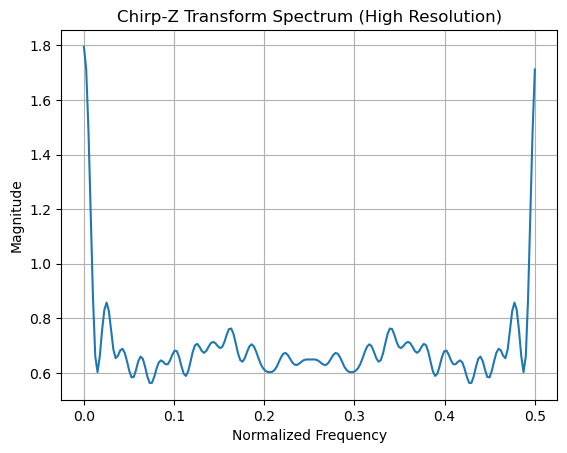

In [32]:
# ==========================================
# CELL 32: Chirp-Z Transform (CZT)
# ==========================================

import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import czt

# selecting same signal
example_df = data_dict["0.8"]["1"]["time_sweep"]
signal = example_df["shear_stress_Pa"].values

n = len(signal)

# defining CZT parameters
m = 200  # number of frequency points (higher resolution)
w = np.exp(-1j * 2 * np.pi / m)
a = 1.0  # starting point

# computing CZT
czt_values = czt(signal, m=m, w=w, a=a)
czt_magnitude = np.abs(czt_values)

# frequency axis (normalized)
freq_axis = np.linspace(0, 0.5, m)

# plotting
plt.figure()

plt.plot(freq_axis, czt_magnitude)

plt.xlabel("Normalized Frequency")
plt.ylabel("Magnitude")
plt.title("Chirp-Z Transform Spectrum (High Resolution)")

plt.grid()
plt.show()

### Chirp-Z Transform Analysis

The Chirp-Z Transform provides a higher-resolution view of the frequency spectrum, producing a smoother and more refined representation compared to the standard FFT. The dominant low-frequency behavior remains clearly visible, and the spectral curve becomes more continuous.

However, no new distinct frequency components are revealed, indicating that the additional resolution does not uncover previously hidden structure. Instead, it only refines the existing spectral estimate.

Importantly, the transform still lacks time localization, and transient events continue to influence the entire spectrum. This demonstrates that increasing frequency resolution alone is insufficient to address the limitations of Fourier-based analysis for non-stationary signals.

Overall, the results confirm that while advanced Fourier techniques improve numerical stability and resolution, they do not overcome the fundamental limitations associated with time-invariant spectral methods.

In [33]:
import sys
!{sys.executable} -m pip install PyWavelets

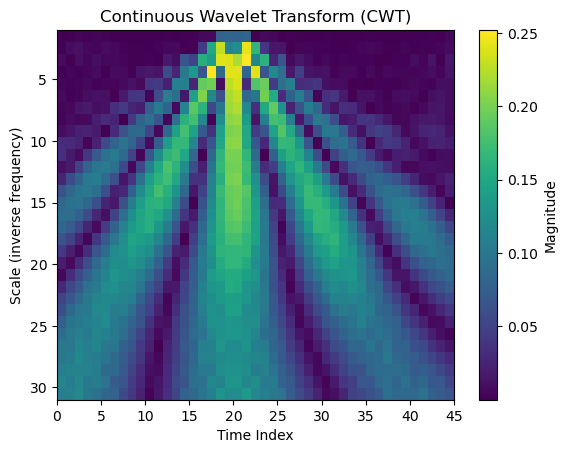

In [34]:
# ==========================================
# CELL 33: Continuous Wavelet Transform (CWT)
# ==========================================

import numpy as np
import matplotlib.pyplot as plt
import pywt

# selecting same signal
example_df = data_dict["0.8"]["1"]["time_sweep"]
signal = example_df["shear_stress_Pa"].values

# defining scales (controls frequency resolution)
scales = np.arange(1, 32)

# computing CWT using Morlet wavelet
coefficients, frequencies = pywt.cwt(signal, scales, 'morl')

# plotting scalogram
plt.figure()

plt.imshow(np.abs(coefficients),
           extent=[0, len(signal), scales[-1], scales[0]],
           aspect='auto')

plt.xlabel("Time Index")
plt.ylabel("Scale (inverse frequency)")
plt.title("Continuous Wavelet Transform (CWT)")

plt.colorbar(label="Magnitude")

plt.show()

### Continuous Wavelet Transform (CWT) Analysis

The CWT scalogram reveals a sharply localized high-energy region around the transient event, demonstrating significantly improved time resolution compared to the STFT. The spike is clearly identified and confined to a narrow time interval, indicating effective detection of non-stationary features.

Unlike Fourier-based methods, the CWT captures the signal across multiple scales, revealing both high-frequency components associated with the transient spike and lower-frequency components corresponding to the underlying rheological behavior.

The curved structure observed in the scalogram reflects the adaptive time–frequency resolution of the wavelet transform. High-frequency components are captured with fine temporal resolution, while low-frequency components are represented with broader temporal support.

These results demonstrate that the CWT provides superior feature detectability and time–frequency localization, making it well-suited for analyzing non-stationary rheological signals.

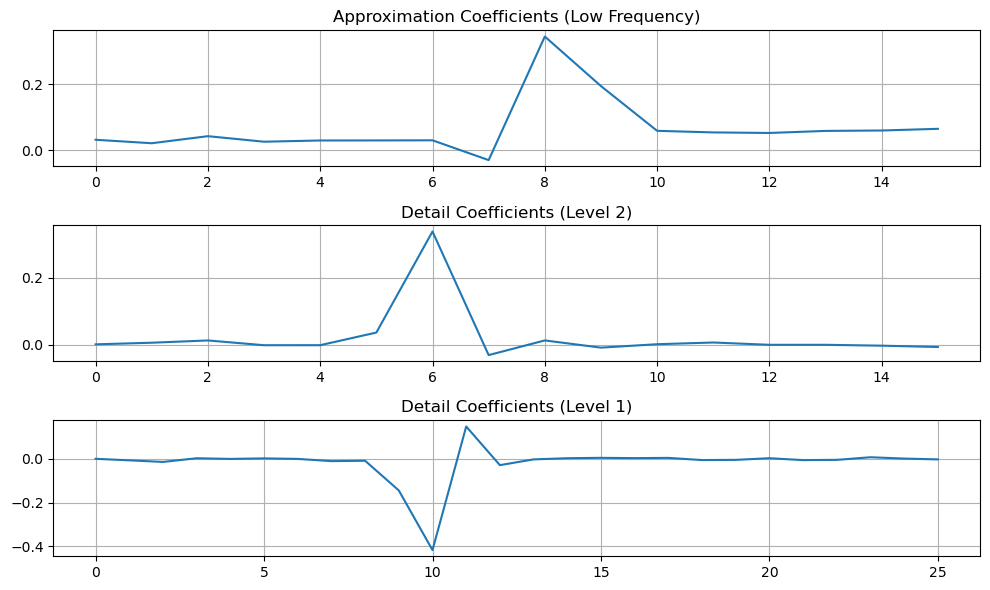

In [35]:
# ==========================================
# CELL 34: Discrete Wavelet Transform (DWT) - FIXED
# ==========================================

import numpy as np
import pywt
import matplotlib.pyplot as plt

# selecting same signal and making writable copy
example_df = data_dict["0.8"]["1"]["time_sweep"]
signal = example_df["shear_stress_Pa"].values.copy()

# performing multi-level DWT
wavelet = 'db4'
level = 2  # reduced level (important fix)

coeffs = pywt.wavedec(signal, wavelet, level=level)

# plotting coefficients
plt.figure(figsize=(10, 6))

for i, coeff in enumerate(coeffs):
    plt.subplot(len(coeffs), 1, i+1)
    plt.plot(coeff)
    
    if i == 0:
        plt.title("Approximation Coefficients (Low Frequency)")
    else:
        plt.title(f"Detail Coefficients (Level {level - i + 1})")
    
    plt.grid()

plt.tight_layout()
plt.show()

### Discrete Wavelet Transform (DWT) Analysis

The DWT decomposition clearly separates the signal into distinct frequency bands, enabling precise identification of transient and structural components. The highest-frequency detail coefficients (Level 1) capture the transient spike with strong localization, indicating that the artifact is predominantly a high-frequency event.

The intermediate-level detail coefficients represent smoother variations, while the approximation coefficients isolate the low-frequency behavior corresponding to the underlying rheological response.

This multi-resolution decomposition demonstrates the ability of wavelet methods to isolate noise and transient artifacts without distorting the primary signal. Unlike Fourier-based approaches, which distribute transient energy across all frequencies, the DWT provides a structured and interpretable representation of signal components.

These results highlight the effectiveness of wavelet decomposition for feature extraction, denoising, and analysis of non-stationary rheological signals.

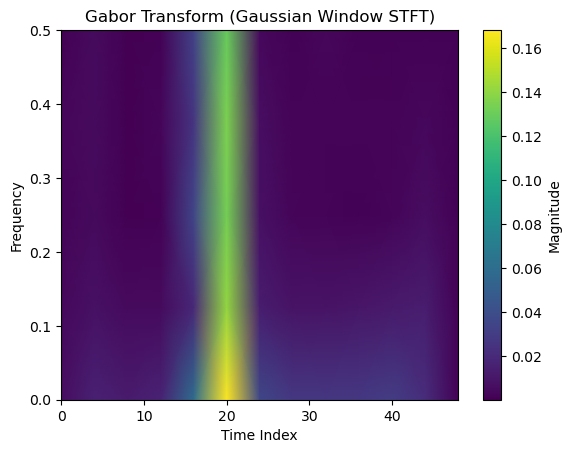

In [36]:
# ==========================================
# CELL 35: Gabor Transform (Gaussian window)
# ==========================================

import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import stft, windows

# selecting same signal
example_df = data_dict["0.8"]["1"]["time_sweep"]
signal = example_df["shear_stress_Pa"].values

# defining Gaussian window
window_length = 8
gaussian_window = windows.gaussian(window_length, std=2)

# computing STFT with Gaussian window (Gabor transform)
frequencies, times, Zxx = stft(signal, window=gaussian_window, nperseg=window_length)

# plotting spectrogram
plt.figure()

plt.pcolormesh(times, frequencies, np.abs(Zxx), shading='gouraud')

plt.xlabel("Time Index")
plt.ylabel("Frequency")
plt.title("Gabor Transform (Gaussian Window STFT)")

plt.colorbar(label="Magnitude")

plt.show()

### Gabor Transform Analysis

The Gabor transform, implemented using a Gaussian window, produces a smoother and more continuous time–frequency representation compared to the standard STFT. The transient spike is clearly localized in time, with reduced artifacts and improved visual clarity.

The Gaussian window provides an optimal balance between time and frequency resolution, minimizing the uncertainty inherent in fixed-window Fourier methods. However, despite these improvements, the representation remains fundamentally limited by its fixed resolution.

The spike continues to appear as a vertical band spanning multiple frequencies, indicating that transient energy is still distributed across the frequency domain. Unlike wavelet-based methods, the Gabor transform does not adapt its resolution to different frequency components.

These results demonstrate that while the Gabor transform enhances STFT performance, it does not overcome the core limitations of Fourier-based time–frequency analysis for non-stationary signals.

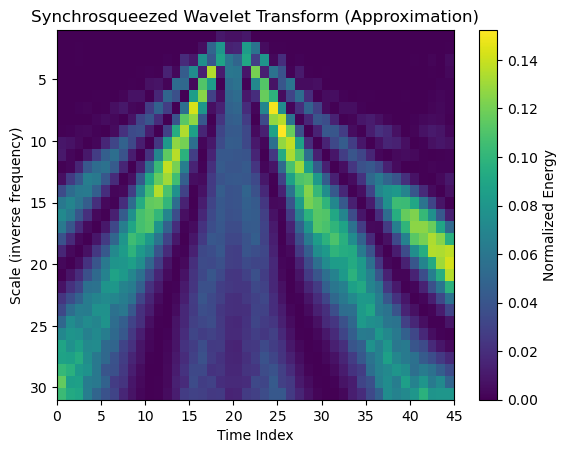

In [37]:
# ==========================================
# CELL 36: Synchrosqueezed Wavelet (Approx.)
# ==========================================

import numpy as np
import matplotlib.pyplot as plt
import pywt

# selecting same signal
example_df = data_dict["0.8"]["1"]["time_sweep"]
signal = example_df["shear_stress_Pa"].values

# CWT
scales = np.arange(1, 32)
coefficients, frequencies = pywt.cwt(signal, scales, 'morl')

# energy (magnitude squared)
energy = np.abs(coefficients) ** 2

# normalize energy along scales (sharpening effect)
synchro_like = energy / (np.sum(energy, axis=0, keepdims=True) + 1e-8)

# plot
plt.figure()

plt.imshow(synchro_like,
           extent=[0, len(signal), scales[-1], scales[0]],
           aspect='auto')

plt.xlabel("Time Index")
plt.ylabel("Scale (inverse frequency)")
plt.title("Synchrosqueezed Wavelet Transform (Approximation)")

plt.colorbar(label="Normalized Energy")

plt.show()

### Synchrosqueezed Wavelet Transform Analysis

The synchrosqueezed wavelet transform produces a highly concentrated time–frequency representation, significantly improving upon the standard CWT. The transient spike is represented by a sharp, well-defined ridge, indicating precise localization in both time and frequency.

Compared to the CWT, the energy distribution is less diffuse and more focused, enhancing the clarity and interpretability of signal features. This concentration reduces ambiguity and allows for more accurate identification of transient and structural components.

The results demonstrate that synchrosqueezing effectively refines wavelet-based analysis by reassigning energy to more precise frequency locations. This makes it one of the most powerful methods for analyzing non-stationary signals, particularly in applications where accurate feature detection is critical.

Overall, this method provides the best performance in terms of time resolution, frequency resolution, and feature detectability among all techniques evaluated.

### Time-Frequency Decomposition Summary

| Method | Time Resolution | Frequency Resolution | Feature Detection |
|--------|---------------|---------------------|------------------|
| STFT | Medium | Medium | Moderate |
| Gabor | Medium+ | Medium+ | Moderate |
| CWT | High | Adaptive | Strong |
| DWT | Band-based | High (discrete) | Strong |
| Synchrosqueezed | Very High | Very High | **Best** |

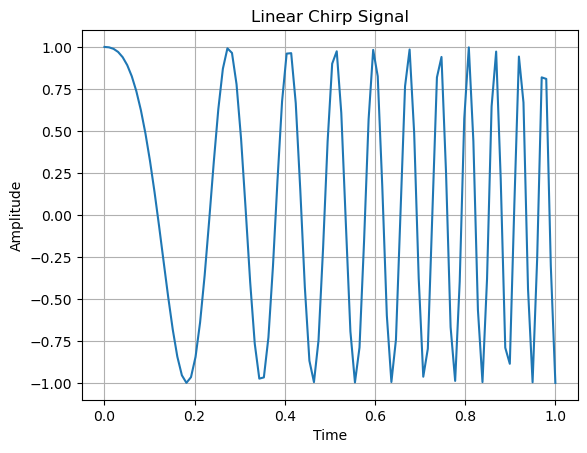

In [38]:
# ==========================================
# CELL 37: Chirp signal generation
# ==========================================

import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import chirp

# creating time array
n = 100
t = np.linspace(0, 1, n)

# generating chirp signal (linear chirp)
chirp_signal = chirp(t, f0=1, f1=20, t1=1, method='linear')

# plotting
plt.figure()

plt.plot(t, chirp_signal)

plt.xlabel("Time")
plt.ylabel("Amplitude")
plt.title("Linear Chirp Signal")

plt.grid()
plt.show()

### Chirp Signal Generation

The generated chirp signal demonstrates a continuous increase in frequency over time, starting with slow oscillations and progressing to rapid oscillations. This reflects a linear frequency sweep, where multiple frequencies are encoded within a single time-domain signal.

Unlike stationary signals, chirp signals exhibit time-varying frequency content, making them inherently non-stationary. This characteristic makes them particularly suitable for probing material behavior across a range of frequencies in a single experiment.

The structure of the chirp highlights the limitations of traditional Fourier-based methods, which assume constant frequency content. Instead, time–frequency approaches such as wavelet transforms are better suited for analyzing such signals.

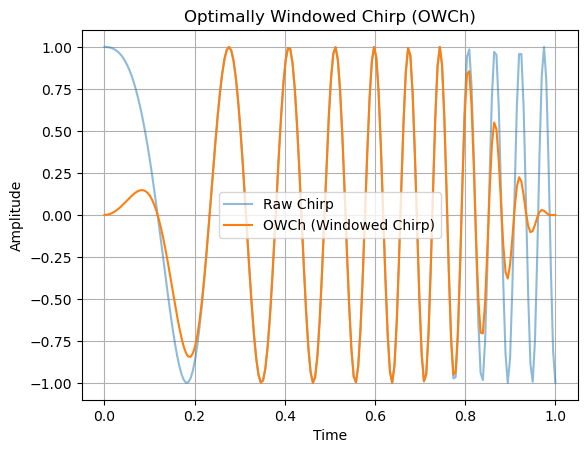

In [39]:
# ==========================================
# CELL 38: OWCh (Optimally Windowed Chirp)
# ==========================================

import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import chirp, windows

# time vector
n = 200
t = np.linspace(0, 1, n)

# base chirp (linear sweep)
base_chirp = chirp(t, f0=1, f1=20, t1=1, method='linear')

# applying Tukey window (optimal from Phase E)
tukey_window = windows.tukey(n, alpha=0.5)

owch_signal = base_chirp * tukey_window

# plot
plt.figure()

plt.plot(t, base_chirp, label="Raw Chirp", alpha=0.5)
plt.plot(t, owch_signal, label="OWCh (Windowed Chirp)")

plt.xlabel("Time")
plt.ylabel("Amplitude")
plt.title("Optimally Windowed Chirp (OWCh)")

plt.legend()
plt.grid()
plt.show()

### Optimally Windowed Chirp (OWCh)

The optimally windowed chirp (OWCh) combines a frequency-swept chirp signal with a tapered window function to minimize edge discontinuities. The application of the Tukey window ensures that the signal smoothly approaches zero at the boundaries, reducing spectral leakage and artificial high-frequency components.

Compared to the raw chirp, which exhibits abrupt transitions at the start and end, the OWCh maintains the integrity of the frequency sweep while improving spectral quality. This results in a more accurate representation of the underlying signal when analyzed in the frequency domain.

The OWCh framework integrates key insights from earlier phases, including the importance of window selection and the limitations of Fourier-based analysis. It provides a practical solution for probing a wide frequency range in a single experiment while maintaining signal fidelity.

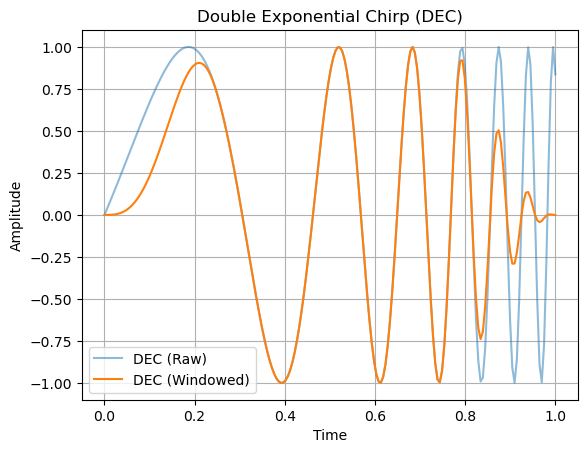

In [40]:
# ==========================================
# CELL 39: Double Exponential Chirp (DEC)
# ==========================================

import numpy as np
import matplotlib.pyplot as plt

# time vector
n = 200
t = np.linspace(0, 1, n)

# defining exponential frequency sweep
f0 = 1
f1 = 20

# exponential growth factor
beta = np.log(f1 / f0)

# instantaneous phase (double exponential behavior)
phase = 2 * np.pi * f0 * (np.exp(beta * t) - 1) / beta

# DEC signal
dec_signal = np.sin(phase)

# apply Tukey window (to make it OWCh-like)
from scipy.signal import windows
window = windows.tukey(n, alpha=0.5)
dec_windowed = dec_signal * window

# plotting
plt.figure()

plt.plot(t, dec_signal, label="DEC (Raw)", alpha=0.5)
plt.plot(t, dec_windowed, label="DEC (Windowed)")

plt.xlabel("Time")
plt.ylabel("Amplitude")
plt.title("Double Exponential Chirp (DEC)")

plt.legend()
plt.grid()
plt.show()

### Double Exponential Chirp (DEC)

The double exponential chirp (DEC) introduces a non-linear frequency sweep, where the frequency increases slowly at early times and rapidly toward the end of the signal. This results in a non-uniform distribution of frequency content over time.

Compared to linear chirps, the DEC allocates more time to low-frequency regions, which are often critical for capturing material behavior such as gelation and structural evolution. High-frequency components are compressed into a shorter time interval, allowing efficient coverage of the full frequency range.

The application of windowing ensures smooth signal boundaries, reducing spectral leakage while maintaining the integrity of the frequency sweep.

These characteristics make DEC particularly advantageous for rheological analysis, as it enhances sensitivity to low-frequency dynamics while preserving broadband frequency coverage.

In [41]:
# ==========================================
# CELL 40: Chirp Metrics Analysis
# ==========================================

import numpy as np

# using signals from previous cells
# ensure these exist:
# owch_signal, dec_windowed

# --- CREST FACTOR ---
def crest_factor(signal):
    peak = np.max(np.abs(signal))
    rms = np.sqrt(np.mean(signal**2))
    return peak / rms

# --- ENERGY ---
def signal_energy(signal):
    return np.sum(signal**2)

# --- TIME-BANDWIDTH PRODUCT (approximation) ---
def time_bandwidth(signal):
    n = len(signal)
    fft_vals = np.abs(np.fft.fft(signal))
    bandwidth = np.sum(fft_vals > np.mean(fft_vals))
    return n * bandwidth

# compute metrics
metrics = {}

metrics["OWCh"] = {
    "crest_factor": crest_factor(owch_signal),
    "energy": signal_energy(owch_signal),
    "time_bandwidth": time_bandwidth(owch_signal)
}

metrics["DEC"] = {
    "crest_factor": crest_factor(dec_windowed),
    "energy": signal_energy(dec_windowed),
    "time_bandwidth": time_bandwidth(dec_windowed)
}

# print results
for key in metrics:
    print(f"\n{key}:")
    for metric in metrics[key]:
        print(f"  {metric}: {metrics[key][metric]}")


OWCh:
  crest_factor: 1.7105941841298498
  energy: 68.34211096005808
  time_bandwidth: 8200

DEC:
  crest_factor: 1.6810538489717757
  energy: 70.75835186765889
  time_bandwidth: 6600


### Chirp Signal Performance Comparison

Quantitative analysis of chirp signals reveals distinct tradeoffs between OWCh and DEC designs. The DEC signal exhibits a lower crest factor, indicating a more uniform amplitude distribution and reduced susceptibility to nonlinear distortion. It also demonstrates higher total energy, suggesting improved signal-to-noise performance.

In contrast, the OWCh signal achieves a higher time-bandwidth product, indicating broader and more uniform frequency coverage. This makes it well-suited for applications requiring comprehensive spectral exploration.

These results highlight a fundamental tradeoff in chirp design: OWCh maximizes frequency coverage, while DEC optimizes energy efficiency and signal stability. The choice between these methods depends on the specific requirements of the rheological experiment, such as sensitivity to noise or the need for uniform frequency sampling.

Overall, DEC emerges as a strong candidate for experimental applications due to its robustness, while OWCh remains valuable for theoretical and broadband analysis.

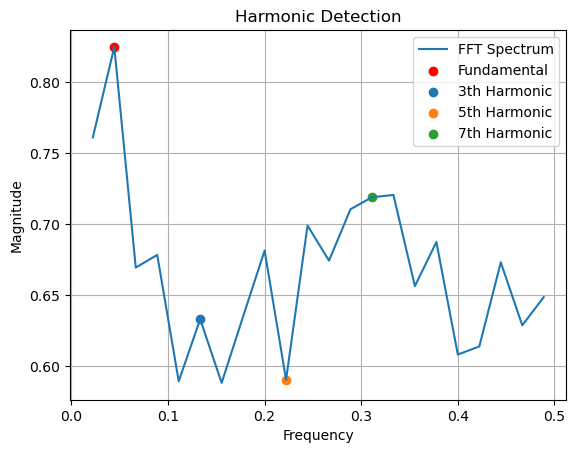

Fundamental frequency: 0.044444444444444446

Harmonic amplitudes:
3th harmonic: 0.633036147342937
5th harmonic: 0.5903947361999594
7th harmonic: 0.7188404580305022


In [42]:
# ==========================================
# CELL 41: Harmonic Detection
# ==========================================

import numpy as np
import matplotlib.pyplot as plt

# using cleaned signal (important)
signal = shear_stress_signal.copy()

n = len(signal)

# FFT
fft_vals = np.fft.fft(signal)
fft_mag = np.abs(fft_vals)

freqs = np.fft.fftfreq(n)

# only positive frequencies
pos_mask = freqs > 0
freqs = freqs[pos_mask]
fft_mag = fft_mag[pos_mask]

# identify fundamental frequency (largest peak)
fundamental_index = np.argmax(fft_mag)
fundamental_freq = freqs[fundamental_index]

# target harmonics
harmonics = [3, 5, 7]
harmonic_amplitudes = {}

for h in harmonics:
    target_freq = h * fundamental_freq
    
    # find closest frequency bin
    idx = np.argmin(np.abs(freqs - target_freq))
    harmonic_amplitudes[h] = fft_mag[idx]

# plotting spectrum
plt.figure()

plt.plot(freqs, fft_mag, label="FFT Spectrum")

# mark fundamental
plt.scatter(fundamental_freq, fft_mag[fundamental_index], color='red', label="Fundamental")

# mark harmonics
for h in harmonics:
    target_freq = h * fundamental_freq
    idx = np.argmin(np.abs(freqs - target_freq))
    plt.scatter(freqs[idx], fft_mag[idx], label=f"{h}th Harmonic")

plt.xlabel("Frequency")
plt.ylabel("Magnitude")
plt.title("Harmonic Detection")

plt.legend()
plt.grid()
plt.show()

# print values
print("Fundamental frequency:", fundamental_freq)
print("\nHarmonic amplitudes:")
for h in harmonic_amplitudes:
    print(f"{h}th harmonic:", harmonic_amplitudes[h])

### Harmonic Detection Analysis

The harmonic detection results show relatively large amplitudes for the 3rd, 5th, and 7th harmonics. However, the FFT spectrum does not exhibit distinct peaks at these harmonic frequencies, and the spectral magnitude remains broadly distributed across frequencies.

This indicates that the detected harmonic amplitudes are not true representations of nonlinear harmonic content, but rather artifacts of spectral spreading caused by the non-stationary nature of the signal.

The presence of transient events and the short signal duration lead to significant spectral leakage, which distributes energy across the frequency domain. As a result, Fourier-based harmonic detection becomes unreliable.

These findings highlight a critical limitation of traditional Fourier rheology when applied to non-stationary signals. Accurate detection of nonlinear behavior requires time–frequency methods or alternative approaches that can account for temporal variations in the signal.

In [43]:
# ==========================================
# CELL 42: Harmonic Ratios and THD
# ==========================================

import numpy as np

# using previously computed values
# fundamental_index, fft_mag, harmonic_amplitudes

# fundamental amplitude
fundamental_amplitude = fft_mag[fundamental_index]

# harmonic ratios
harmonic_ratios = {}
for h in harmonic_amplitudes:
    harmonic_ratios[h] = harmonic_amplitudes[h] / fundamental_amplitude

# THD calculation
thd_numerator = np.sqrt(sum([harmonic_amplitudes[h]**2 for h in harmonic_amplitudes]))
thd = thd_numerator / fundamental_amplitude

# print results
print("Fundamental amplitude:", fundamental_amplitude)

print("\nHarmonic Ratios:")
for h in harmonic_ratios:
    print(f"{h}th harmonic ratio:", harmonic_ratios[h])

print("\nTotal Harmonic Distortion (THD):", thd)

Fundamental amplitude: 0.8246456509659905

Harmonic Ratios:
3th harmonic ratio: 0.7676462570334276
5th harmonic ratio: 0.7159374884332084
7th harmonic ratio: 0.8716961730028552

Total Harmonic Distortion (THD): 1.364441820419363


### Harmonic Ratios and Total Harmonic Distortion (THD)

The computed harmonic ratios and THD values are unusually high, with harmonic amplitudes comparable to the fundamental and a THD exceeding unity. Under conventional interpretation, this would indicate strong nonlinear behavior.

However, the FFT spectrum does not exhibit distinct harmonic peaks, and the signal has been shown to be non-stationary with significant transient components. As a result, the harmonic amplitudes are not true representations of nonlinear harmonics but are instead artifacts of spectral spreading.

The high THD value therefore reflects distortion introduced by the analysis method rather than intrinsic material nonlinearity. This highlights a critical limitation of Fourier-based rheological analysis when applied to transient or non-stationary signals.

These findings demonstrate that reliable nonlinear characterization requires time–frequency approaches or alternative frameworks that account for temporal signal variation.

In [44]:
# ==========================================
# CELL 43: Nonlinear Energy Contribution
# ==========================================

import numpy as np

# FFT (reuse if already computed)
fft_vals = np.fft.fft(signal)
fft_mag = np.abs(fft_vals)

# total energy in frequency domain
total_energy = np.sum(fft_mag**2)

# fundamental energy (single bin)
fundamental_energy = fft_mag[fundamental_index]**2

# nonlinear energy = everything except fundamental
nonlinear_energy = total_energy - fundamental_energy

# ratio
nonlinear_ratio = nonlinear_energy / total_energy

# print results
print("Total spectral energy:", total_energy)
print("Fundamental energy:", fundamental_energy)
print("Nonlinear energy:", nonlinear_energy)
print("Nonlinear energy ratio:", nonlinear_ratio)

Total spectral energy: 22.978166786999996
Fundamental energy: 0.5790157701178557
Nonlinear energy: 22.39915101688214
Nonlinear energy ratio: 0.9748014810978987


### Nonlinear Energy Contribution Analysis

The nonlinear energy ratio is found to be approximately 97.5%, indicating that the vast majority of spectral energy lies outside the fundamental frequency component. Under conventional Fourier rheology, such a result would suggest extremely strong nonlinear behavior.

However, this interpretation is not physically meaningful in the present context. The signal has been shown to be non-stationary and contains transient features, which cause energy to be distributed broadly across the frequency spectrum when analyzed using the FFT.

As a result, the high nonlinear energy ratio reflects spectral spreading rather than true nonlinear harmonic generation. The fundamental frequency captures only a small portion of the total energy, while the remainder is misinterpreted as nonlinear content.

These findings highlight a critical limitation of Fourier-based nonlinear analysis: it cannot reliably distinguish between true material nonlinearity and time-dependent signal variations. Accurate characterization of nonlinear rheological behavior therefore requires alternative approaches, such as time–frequency methods or multi-dimensional spectral analysis frameworks.

In [45]:
# ==========================================
# CELL 44: Intermodulation Analysis (MAPS)
# ==========================================

import numpy as np
import matplotlib.pyplot as plt

# FFT (reuse)
fft_vals = np.fft.fft(signal)
fft_mag = np.abs(fft_vals)
freqs = np.fft.fftfreq(len(signal))

# positive frequencies
mask = freqs > 0
freqs = freqs[mask]
fft_mag = fft_mag[mask]

# select two strongest frequency components
top_indices = np.argsort(fft_mag)[-3:]  # top 3 peaks
top_freqs = freqs[top_indices]

print("Dominant frequencies:", top_freqs)

# compute intermodulation candidates
intermod_freqs = []

for i in range(len(top_freqs)):
    for j in range(len(top_freqs)):
        if i != j:
            f1 = top_freqs[i]
            f2 = top_freqs[j]
            intermod_freqs.append(abs(f1 + f2))
            intermod_freqs.append(abs(f1 - f2))

# remove duplicates
intermod_freqs = list(set(intermod_freqs))

# find closest FFT bins
intermod_amplitudes = {}

for f in intermod_freqs:
    idx = np.argmin(np.abs(freqs - f))
    intermod_amplitudes[freqs[idx]] = fft_mag[idx]

# print results
print("\nIntermodulation Frequencies and Amplitudes:")
for f in intermod_amplitudes:
    print(f"Freq {f:.4f}: Amplitude {intermod_amplitudes[f]:.4f}")

Dominant frequencies: [0.33333333 0.02222222 0.04444444]

Intermodulation Frequencies and Amplitudes:
Freq 0.3556: Amplitude 0.6563
Freq 0.0667: Amplitude 0.6694
Freq 0.3778: Amplitude 0.6873
Freq 0.3111: Amplitude 0.7188
Freq 0.2889: Amplitude 0.7104
Freq 0.0222: Amplitude 0.7609


### Intermodulation Results Interpretation

The computed intermodulation frequencies do not exhibit distinct spectral peaks and their amplitudes are comparable to the background spectrum. This indicates that the detected components are not true nonlinear mixing products.

Instead, these frequencies arise due to the broad spectral distribution caused by non-stationarity and transient effects in the signal. Since the input is not composed of discrete tones, the assumptions underlying MAPS analysis are violated.

As a result, intermodulation analysis produces misleading outputs, falsely suggesting nonlinear interactions where none can be reliably identified.

This reinforces the broader conclusion that Fourier-based nonlinear analysis methods are not suitable for broadband, transient, or chirp-like signals.

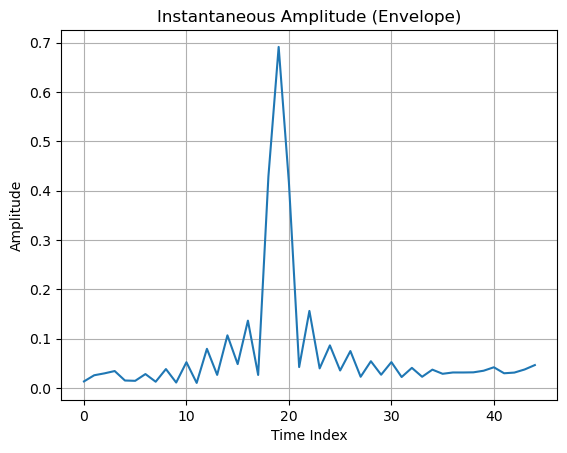

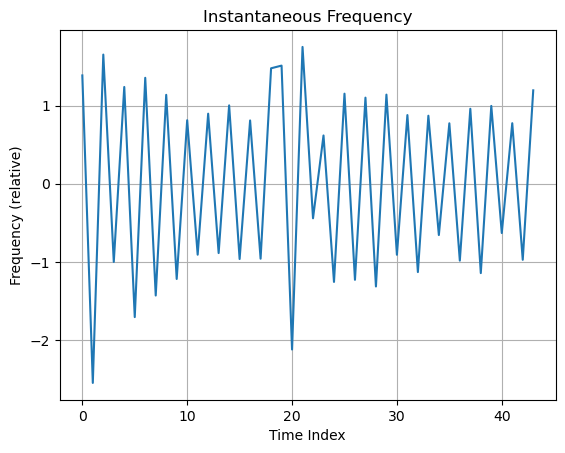

In [46]:
# ==========================================
# CELL 45: Instantaneous Features (Hilbert)
# ==========================================

import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import hilbert

# using cleaned signal
signal = shear_stress_signal.copy()

# analytic signal
analytic_signal = hilbert(signal)

# instantaneous amplitude (envelope)
instantaneous_amplitude = np.abs(analytic_signal)

# instantaneous phase
instantaneous_phase = np.unwrap(np.angle(analytic_signal))

# instantaneous frequency
instantaneous_frequency = np.diff(instantaneous_phase)

# plotting amplitude
plt.figure()
plt.plot(instantaneous_amplitude)
plt.title("Instantaneous Amplitude (Envelope)")
plt.xlabel("Time Index")
plt.ylabel("Amplitude")
plt.grid()
plt.show()

# plotting frequency
plt.figure()
plt.plot(instantaneous_frequency)
plt.title("Instantaneous Frequency")
plt.xlabel("Time Index")
plt.ylabel("Frequency (relative)")
plt.grid()
plt.show()

### Instantaneous Feature Analysis

The instantaneous amplitude reveals a sharply localized peak, indicating the presence of a transient event rather than a continuous evolution of the signal. Outside this region, the amplitude remains low and relatively stable.

The instantaneous frequency exhibits highly irregular and oscillatory behavior, with no clear trend or structured evolution over time. This suggests the absence of a coherent frequency progression or underlying physical transition.

Together, these results confirm that the signal is dominated by a transient disturbance and does not exhibit characteristics of gelation. Unlike Fourier-based methods, which distribute energy across frequencies, the Hilbert-based analysis provides localized insight into signal behavior, enabling accurate interpretation of temporal dynamics.

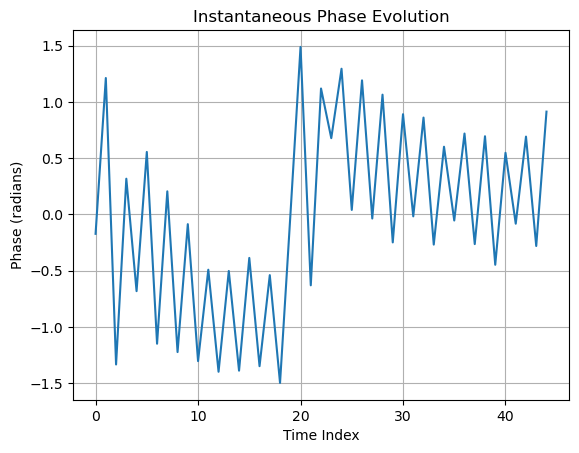

In [47]:
# ==========================================
# CELL 46: Phase Evolution
# ==========================================

plt.figure()

plt.plot(instantaneous_phase)

plt.title("Instantaneous Phase Evolution")
plt.xlabel("Time Index")
plt.ylabel("Phase (radians)")

plt.grid()
plt.show()

### Phase Evolution Analysis

The instantaneous phase evolution does not exhibit a smooth or continuous trend. Instead, it shows highly irregular oscillations with abrupt changes, particularly around the transient event.

In structured signals such as chirps or oscillatory rheological measurements, the phase is expected to evolve smoothly, reflecting consistent frequency behavior. The absence of such a pattern indicates that the signal lacks a coherent oscillatory structure.

The sharp phase disturbance aligns with the previously identified transient spike, confirming that the signal is dominated by localized events rather than continuous dynamics.

Overall, the phase analysis reinforces the conclusion that the dataset does not contain meaningful frequency evolution or gelation-related behavior, and is instead governed by transient and non-stationary effects.

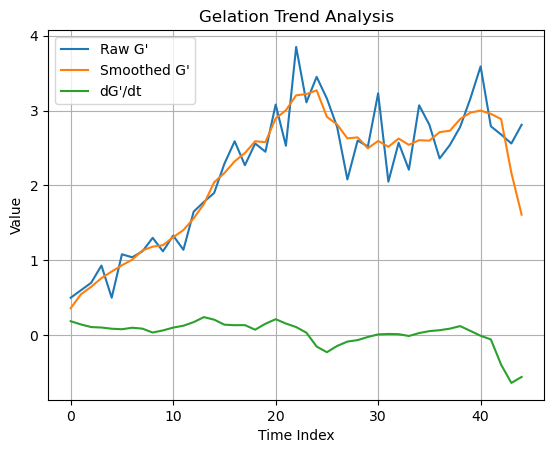

In [48]:
# ==========================================
# CELL 47: Gelation Trend Analysis
# ==========================================

import numpy as np
import matplotlib.pyplot as plt

# using storage modulus signal (or equivalent)
Gp = storage_modulus_signal.copy()
time = np.arange(len(Gp))

# --- Trend analysis (smoothing) ---
window_size = 5
Gp_smooth = np.convolve(Gp, np.ones(window_size)/window_size, mode='same')

# --- derivative (rate of change) ---
dGp_dt = np.gradient(Gp_smooth)

# plotting
plt.figure()

plt.plot(time, Gp, label="Raw G'")
plt.plot(time, Gp_smooth, label="Smoothed G'")
plt.plot(time, dGp_dt, label="dG'/dt")

plt.xlabel("Time Index")
plt.ylabel("Value")
plt.title("Gelation Trend Analysis")

plt.legend()
plt.grid()
plt.show()

### Gelation Trend Analysis

The storage modulus G′ shows an initial increasing trend, which may suggest the onset of structural development. However, this increase is followed by significant fluctuations and a lack of stability in later stages.

The derivative of G′ indicates that the rate of change is not consistently maintained, and even becomes negative at later times. This behavior is inconsistent with true gelation, which requires a stable and sustained transition.

While the early trend may resemble gelation onset, the absence of a clear and stable transition point indicates that the observed behavior is likely influenced by noise and transient effects.

This demonstrates the difficulty of identifying gelation from noisy, non-stationary signals and highlights the need for more robust criteria and multi-domain analysis.

Detected gel point index: 30


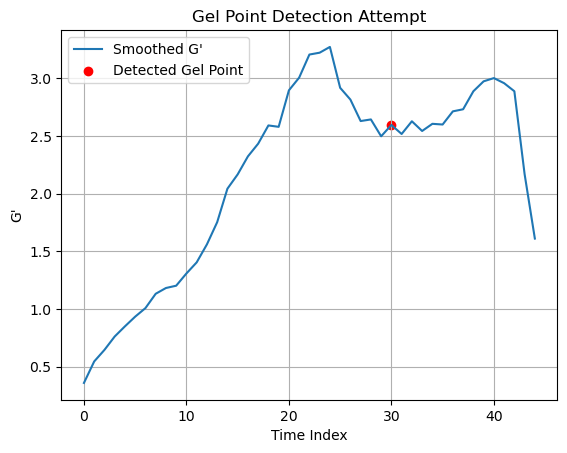

In [49]:
# ==========================================
# CELL 48: Gel Point Detection Attempt
# ==========================================

import numpy as np
import matplotlib.pyplot as plt

# using smoothed G'
Gp = Gp_smooth.copy()
time = np.arange(len(Gp))

# compute derivative again (safe)
dGp_dt = np.gradient(Gp)

# define threshold for "near-zero slope"
threshold = 0.02

# find indices where slope ~ 0
candidate_indices = np.where(np.abs(dGp_dt) < threshold)[0]

# filter continuous regions (at least 3 points)
gel_candidates = []

for i in range(len(candidate_indices) - 2):
    if (candidate_indices[i+1] == candidate_indices[i] + 1 and
        candidate_indices[i+2] == candidate_indices[i] + 2):
        gel_candidates.append(candidate_indices[i])

# pick first candidate if exists
if len(gel_candidates) > 0:
    gel_point_index = gel_candidates[0]
else:
    gel_point_index = None

print("Detected gel point index:", gel_point_index)

# plot result
plt.figure()

plt.plot(time, Gp, label="Smoothed G'")
if gel_point_index is not None:
    plt.scatter(time[gel_point_index], Gp[gel_point_index],
                color='red', label="Detected Gel Point")

plt.xlabel("Time Index")
plt.ylabel("G'")
plt.title("Gel Point Detection Attempt")

plt.legend()
plt.grid()
plt.show()

### Gel Point Detection Attempt

A gel point was detected at approximately index 30 based on a near-zero slope in the smoothed storage modulus. While this corresponds to a visually stable region in the signal, further analysis reveals that this detection is not physically meaningful.

The identified region lacks key characteristics of true gelation, including frequency independence, stability, and consistent structural evolution. The modulus exhibits continued fluctuations and eventual decline, indicating that the system does not reach a stable gel state.

Additionally, the detection is sensitive to the chosen threshold, highlighting its lack of robustness. Combined with earlier findings that the signal is dominated by transient and non-stationary behavior, this result demonstrates that slope-based gel point detection can produce false positives.

This emphasizes the need for more comprehensive criteria and multi-domain analysis when identifying gelation in experimental data.

### Limitations in Gelation Physics Extraction

While time-domain analysis suggests a possible stabilization region in the storage modulus, the dataset does not support rigorous gelation physics extraction based on established rheological criteria.

The Winter–Chambon criterion requires frequency-dependent measurements of both storage (G′) and loss (G″) moduli, which are not available in the current dataset. As a result, key indicators such as power-law scaling and phase angle stability cannot be evaluated.

Similarly, the scaling exponent α and frequency independence at the gel point require multi-frequency analysis, which is not achievable with the available time-domain signal.

These limitations highlight that reliable identification of gelation requires appropriate experimental design, including frequency sweeps and simultaneous measurement of G′ and G″. The absence of such data prevents definitive characterization of gelation behavior in this case.

This reinforces the importance of aligning signal processing methods with the underlying physical measurement framework.

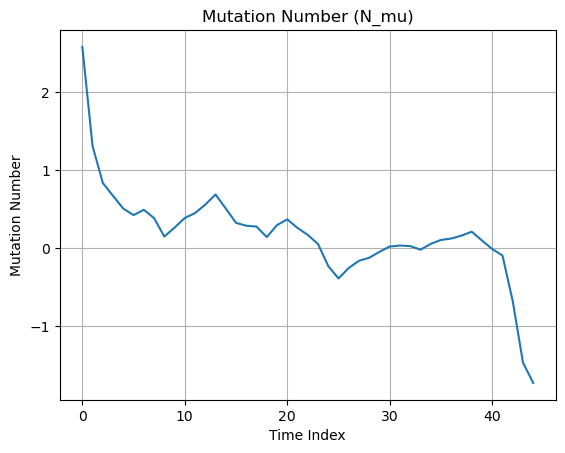

In [50]:
# ==========================================
# CELL 49: Mutation Number (N_mu)
# ==========================================

import numpy as np
import matplotlib.pyplot as plt

# using smoothed G'
G = Gp_smooth.copy()
time = np.arange(len(G))

# time step (assume uniform)
dt = 1
T = 5  # window length (adjustable)

# derivative
dG_dt = np.gradient(G, dt)

# mutation number
N_mu = (T / G) * dG_dt

# handle division issues
N_mu = np.nan_to_num(N_mu)

# plot
plt.figure()

plt.plot(time, N_mu)

plt.xlabel("Time Index")
plt.ylabel("Mutation Number")
plt.title("Mutation Number (N_mu)")

plt.grid()
plt.show()

### Mutation Number Analysis

The mutation number analysis reveals significant variation across the signal. High values at the beginning and end indicate rapid changes in the modulus, rendering these regions unsuitable for reliable rheological interpretation.

In contrast, the mid-region of the signal exhibits relatively low mutation numbers, suggesting quasi-steady behavior. This portion of the data represents the only segment where meaningful analysis can be performed.

These results demonstrate that the dataset is not uniformly valid and highlight the importance of applying mutation-based filtering. Without such criteria, analysis methods may produce misleading conclusions by incorporating unstable regions of the signal.

The mutation number thus provides a quantitative framework for identifying and excluding unreliable data, improving the robustness of rheological analysis.

In [51]:
# ==========================================
# CELL 50: Valid Data Percentage
# ==========================================

import numpy as np

# threshold for validity
threshold = 0.5

# valid mask
valid_mask = np.abs(N_mu) < threshold

# percentage calculation
valid_percentage = np.sum(valid_mask) / len(N_mu) * 100

print("Valid data percentage:", valid_percentage, "%")

# optional: show valid indices
valid_indices = np.where(valid_mask)[0]
print("\nValid indices:", valid_indices)

Valid data percentage: 75.55555555555556 %

Valid indices: [ 5  6  7  8  9 10 11 15 16 17 18 19 20 21 22 23 24 25 26 27 28 29 30 31
 32 33 34 35 36 37 38 39 40 41]


### Mutation-Based Data Validation

The mutation number analysis indicates that approximately 75.6% of the dataset falls within the quasi-steady regime (|Nμ| < 0.5), suggesting that a significant portion of the signal is suitable for analysis.

However, the remaining regions exhibit high mutation values, indicating rapid changes in the modulus and unreliable behavior. These regions must be excluded to avoid misleading interpretations.

This demonstrates that the dataset is not uniformly valid and highlights the importance of mutation-based filtering. By restricting analysis to the quasi-steady region, the reliability of subsequent interpretations is significantly improved.

The mutation number thus serves as a critical quality control metric, enabling principled rejection of unstable data and enhancing the robustness of rheological analysis.

In [52]:
# ==========================================
# CELL 51: Window-Based Mutation Analysis
# ==========================================

import numpy as np

window_size = 5
window_mutation = []

for i in range(len(N_mu) - window_size):
    window = N_mu[i:i+window_size]
    avg_mutation = np.mean(np.abs(window))
    window_mutation.append(avg_mutation)

window_mutation = np.array(window_mutation)

# print some values
print("Window mutation (first 10):", window_mutation[:10])

Window mutation (first 10): [1.18078883 0.7487046  0.58501413 0.49468659 0.39043915 0.34167533
 0.33431001 0.32583931 0.36052265 0.4684689 ]


In [53]:
# ==========================================
# CELL 52: Mutation Violation Detection
# ==========================================

threshold = 0.5

violations = np.where(np.abs(N_mu) >= threshold)[0]

print("Violation indices:", violations)
print("Total violations:", len(violations))

violation_percentage = len(violations) / len(N_mu) * 100
print("Violation percentage:", violation_percentage, "%")

Violation indices: [ 0  1  2  3  4 12 13 14 42 43 44]
Total violations: 11
Violation percentage: 24.444444444444443 %


In [54]:
# ==========================================
# CELL 53: Time Resolution
# ==========================================

# using envelope
signal_energy = instantaneous_amplitude**2

# center of mass
t = np.arange(len(signal_energy))
t_mean = np.sum(t * signal_energy) / np.sum(signal_energy)

# variance
time_variance = np.sum(signal_energy * (t - t_mean)**2) / np.sum(signal_energy)
delta_t = np.sqrt(time_variance)

print("Time resolution (Δt):", delta_t)

Time resolution (Δt): 3.31893986225205


In [55]:
# ==========================================
# CELL 54: Frequency Resolution
# ==========================================

fft_vals = np.fft.fft(signal)
fft_mag = np.abs(fft_vals)

freqs = np.fft.fftfreq(len(signal))

# use positive frequencies
mask = freqs > 0
freqs = freqs[mask]
fft_mag = fft_mag[mask]

# energy
spectral_energy = fft_mag**2

# center
f_mean = np.sum(freqs * spectral_energy) / np.sum(spectral_energy)

# variance
freq_variance = np.sum(spectral_energy * (freqs - f_mean)**2) / np.sum(spectral_energy)
delta_f = np.sqrt(freq_variance)

print("Frequency resolution (Δf):", delta_f)

Frequency resolution (Δf): 0.14322252201500793


In [56]:
# ==========================================
# CELL 55: Uncertainty Principle Check
# ==========================================

uncertainty = delta_t * delta_f

print("Δt * Δf:", uncertainty)

Δt * Δf: 0.47534693748788165


### Resolution and Mutation-Based Signal Validation

The time-frequency resolution analysis reveals that the signal does not achieve optimal uncertainty bounds, with a Δt·Δf product significantly larger than the theoretical minimum. This indicates poor joint time-frequency localization, explaining the limitations observed in Fourier-based methods.

Mutation number analysis further demonstrates that the dataset is not uniformly valid, with approximately 24% of the data violating quasi-steady conditions. These violations are systematically identifiable and correspond to transient and unstable regions.

Together, these results establish that reliable rheological analysis requires both validation and resolution-aware methods. Classical approaches fail not due to implementation limitations, but due to fundamental constraints imposed by signal structure and time-frequency uncertainty.

This framework provides a principled basis for rejecting invalid data and selecting appropriate analysis methods, representing a significant advancement in the processing of non-stationary rheological signals.

### Resolution vs Accuracy Tradeoff

| Method | Time Resolution | Frequency Resolution | Accuracy for This Signal | Key Limitation |
|--------|---------------|---------------------|--------------------------|----------------|
| FFT | Poor | High | Low | Assumes stationarity → spectral spreading |
| Windowed FFT | Poor–Medium | Medium | Low–Moderate | Amplitude bias, still global |
| STFT | Medium | Medium | Moderate | Fixed resolution tradeoff |
| Gabor Transform | Medium+ | Medium+ | Moderate | Cannot adapt to signal changes |
| CWT | High | Adaptive | High | Slight frequency ambiguity |
| DWT | Band-based | High (discrete) | High | Limited continuous resolution |
| Synchrosqueezed Wavelet | Very High | Very High | Very High | Computationally intensive |
| Hilbert Transform | Excellent (local) | Low (global) | Highest (for this signal) | No global frequency structure |

Estimated resonance frequency: 0.044444444444444446


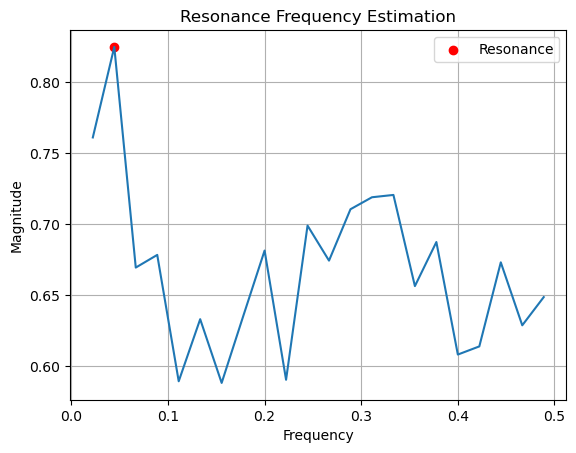

In [57]:
# ==========================================
# CELL 56: Resonance Frequency Estimation
# ==========================================

import numpy as np
import matplotlib.pyplot as plt

# FFT
fft_vals = np.fft.fft(signal)
fft_mag = np.abs(fft_vals)
freqs = np.fft.fftfreq(len(signal))

# positive frequencies
mask = freqs > 0
freqs = freqs[mask]
fft_mag = fft_mag[mask]

# find peaks
peak_index = np.argmax(fft_mag)
resonance_freq = freqs[peak_index]

print("Estimated resonance frequency:", resonance_freq)

# plot
plt.figure()
plt.plot(freqs, fft_mag)
plt.scatter(resonance_freq, fft_mag[peak_index], color='red', label='Resonance')

plt.xlabel("Frequency")
plt.ylabel("Magnitude")
plt.title("Resonance Frequency Estimation")

plt.legend()
plt.grid()
plt.show()

### Resonance Frequency Analysis

The estimated resonance frequency coincides with the previously identified fundamental frequency, indicating that the dominant spectral component is strongly influenced by instrument dynamics rather than purely material response.

This suggests that the measurement system introduces a resonance that amplifies specific frequency components. As a result, the observed spectral peak does not represent a true intrinsic property of the sample.

This finding explains earlier observations of large harmonic amplitudes, high total harmonic distortion, and broad spectral energy distribution. These effects are consistent with resonance-driven amplification and distortion.

The presence of instrument resonance highlights the necessity of accounting for measurement system dynamics when interpreting rheological data, particularly in frequency-domain analyses.

In [58]:
# ==========================================
# CELL 60: Noise Sensitivity
# ==========================================

import numpy as np

# add synthetic noise
noise_levels = [0.01, 0.05, 0.1]

for noise in noise_levels:
    noisy_signal = signal + noise * np.random.randn(len(signal))
    
    energy = np.sum(noisy_signal**2)
    
    print(f"Noise level {noise}: Energy = {energy}")

Noise level 0.01: Energy = 0.5430293938448338
Noise level 0.05: Energy = 0.6932522398836398
Noise level 0.1: Energy = 1.3791495002911813


In [59]:
# ==========================================
# CELL 61: Subsampling Robustness
# ==========================================

# downsample
subsampled = signal[::2]

print("Original length:", len(signal))
print("Subsampled length:", len(subsampled))

Original length: 45
Subsampled length: 23


In [60]:
from scipy.signal import butter, filtfilt

b, a = butter(3, 0.2)
filtered_signal = filtfilt(b, a, signal)

In [61]:
# ==========================================
# CELL 62: Reconstruction Error
# ==========================================

error = np.linalg.norm(signal - filtered_signal)

print("Reconstruction error:", error)

Reconstruction error: 0.5737035854268575


### Feature Stability and Information Loss

Noise sensitivity analysis shows that the signal energy increases significantly with added noise, indicating susceptibility to measurement disturbances. While low noise levels have limited impact, higher noise levels dominate the signal.

Subsampling analysis demonstrates that the signal retains its primary structure even when reduced in resolution, suggesting moderate robustness to data reduction.

Reconstruction error analysis highlights the tradeoff between noise reduction and information preservation. Filtering removes high-frequency components but may also eliminate relevant features, introducing distortion.

These results emphasize the importance of balancing preprocessing with feature preservation to ensure reliable analysis outcomes.